In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Setup complete.")

Setup complete.


In [ ]:
# Loading Data 
df = pd.read_csv("dataset.csv")

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
df.head()

Shape: (114000, 21)

Columns: ['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [ ]:
# Quick inspection
print("Data types:\n", df.dtypes)
print("\nMissing values per column:\n", df.isnull().sum())
print("\nNumber of unique genres:", df["track_genre"].nunique())
print("\nFirst few genres:", df["track_genre"].unique()[:10])

Data types:
 Unnamed: 0            int64
track_id             object
artists              object
album_name           object
track_name           object
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre          object
dtype: object

Missing values per column:
 Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
live

In [ ]:
# Defining our feature set
AUDIO_FEATURES = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "duration_ms"
]


df[AUDIO_FEATURES].describe()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,1.140000e+05
mean,0.566800,0.641383,-8.258960,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,2.280292e+05
std,0.173542,0.251529,5.029337,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,1.072977e+05
min,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00
25%,0.456000,0.472000,-10.013000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,1.740660e+05
50%,0.580000,0.685000,-7.004000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,2.129060e+05
75%,0.695000,0.854000,-5.003000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,2.615060e+05
max,0.985000,1.000000,4.532000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.237295e+06


PHASE 2: Distribution Analysis

In [6]:
import os
os.makedirs("figures", exist_ok=True)
print("Figures folder ready.")

Figures folder ready.


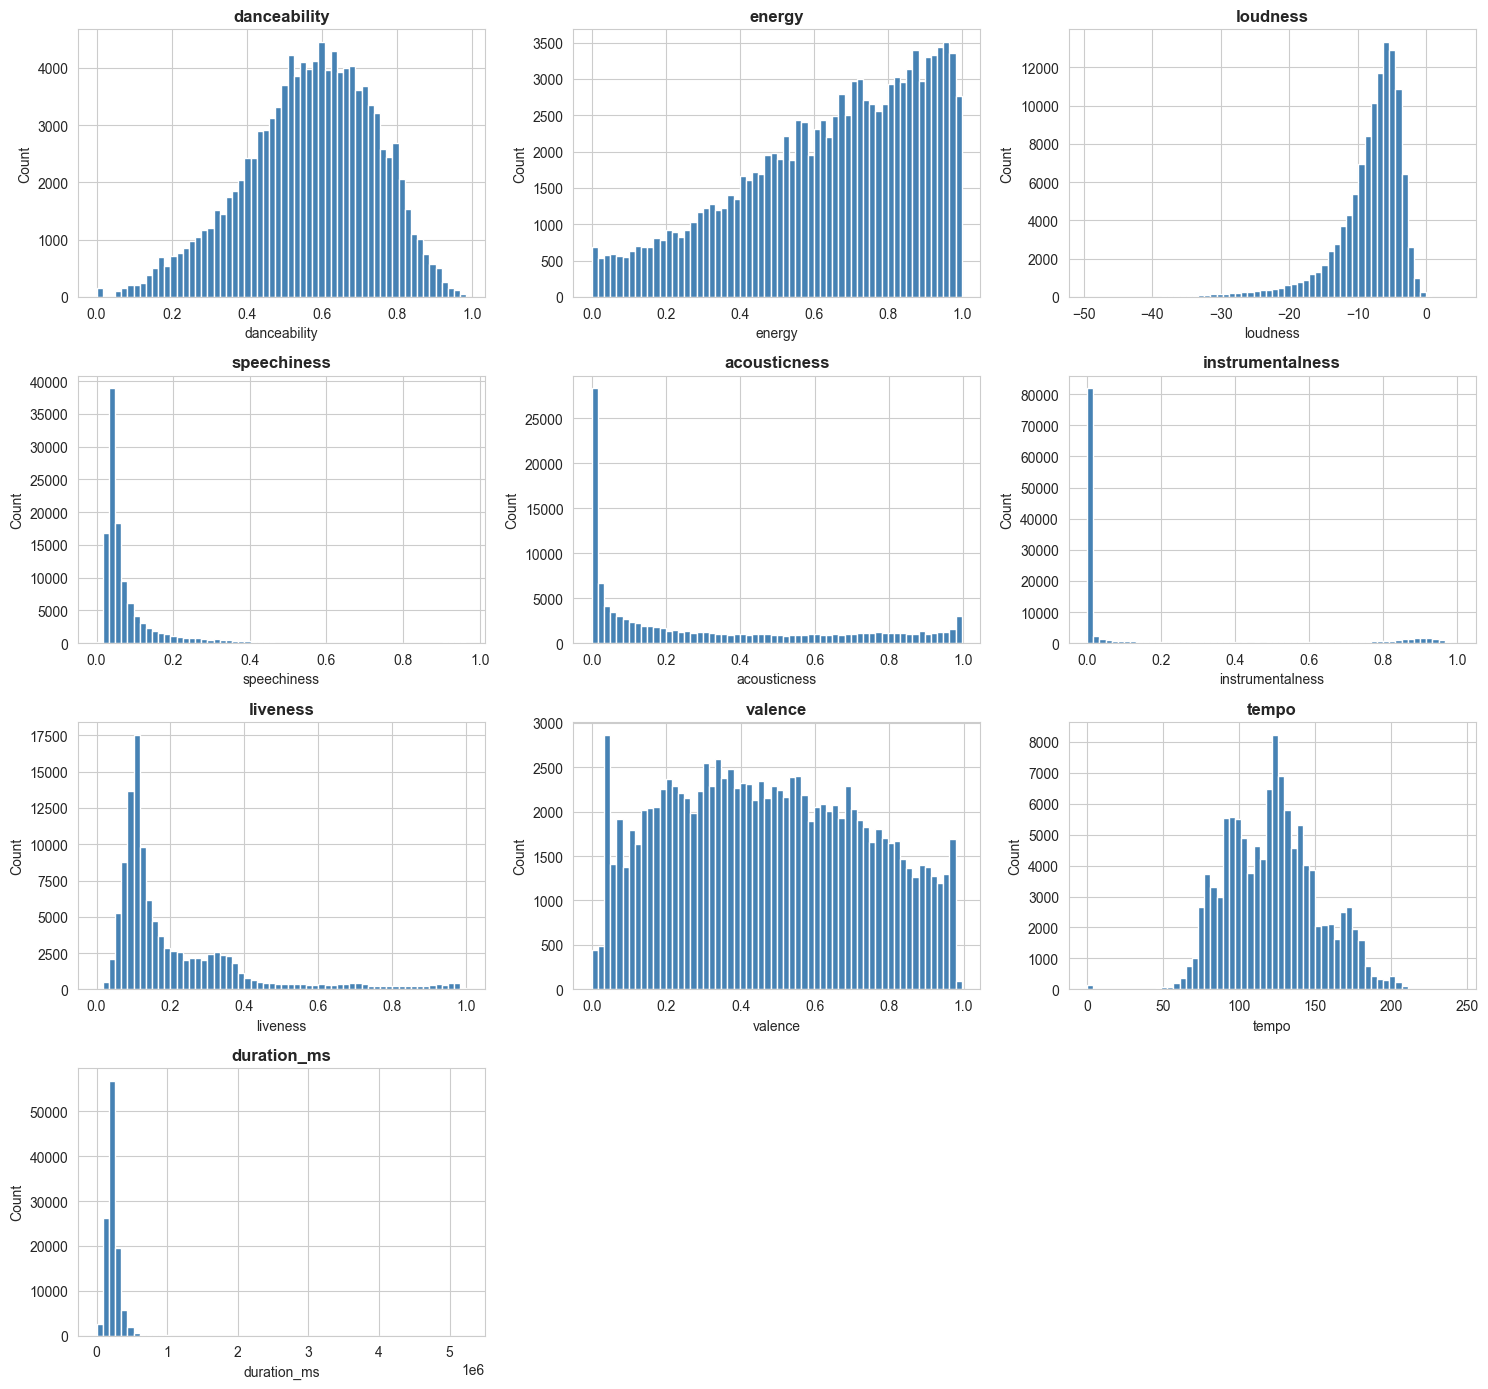

In [ ]:
# Histograms for all audio features 
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
axes = axes.flatten()

for i, feature in enumerate(AUDIO_FEATURES):
    axes[i].hist(df[feature], bins=60, color="steelblue", edgecolor="white")
    axes[i].set_title(feature, fontsize=12, fontweight="bold")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Count")

for j in range(len(AUDIO_FEATURES), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.savefig("figures/01_feature_distributions.png", dpi=120, bbox_inches="tight")
plt.show()

In [9]:
from scipy.stats import skew, kurtosis

stats_df = pd.DataFrame({
    "mean": df[AUDIO_FEATURES].mean(),
    "std": df[AUDIO_FEATURES].std(),
    "skewness": df[AUDIO_FEATURES].apply(skew),
    "kurtosis": df[AUDIO_FEATURES].apply(kurtosis)
}).round(3)

stats_df

stats_df.to_csv("figures/distribution_stats.csv")

Subset shape: (10000, 21)


C:\Users\sride\AppData\Local\Temp\ipykernel_17244\3370732924.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\sride\AppData\Local\Temp\ipykernel_17244\3370732924.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\sride\AppData\Local\Temp\ipykernel_17244\3370732924.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\sride\AppData\Local\Temp\ipykernel_17244\3370732924.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `h

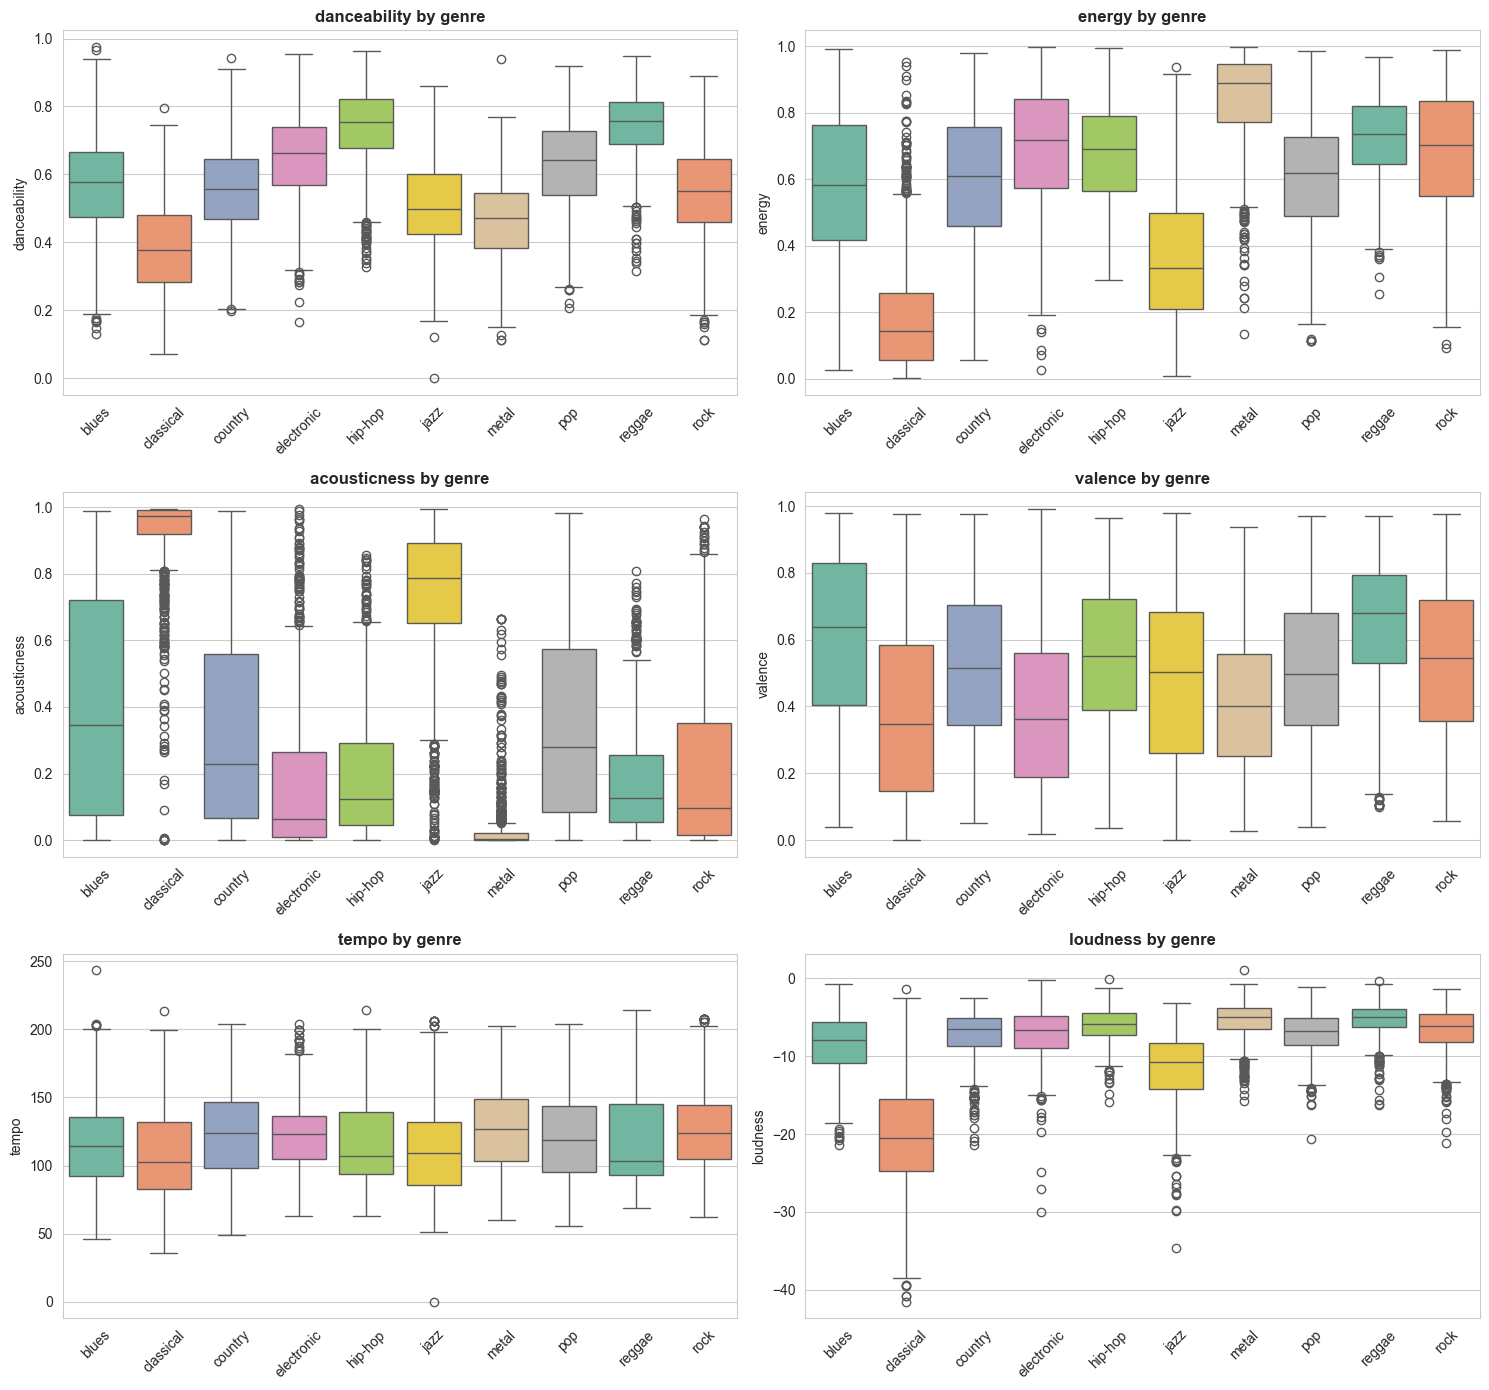

In [ ]:
# Picking a diverse subset of genres for visualization
SELECTED_GENRES = [
    "classical", "jazz", "rock", "pop", "hip-hop",
    "electronic", "country", "metal", "reggae", "blues"
]

# Filtering dataset to just these genres
df_subset = df[df["track_genre"].isin(SELECTED_GENRES)].copy()
print(f"Subset shape: {df_subset.shape}")

# Boxplots: how features vary across genres
key_features = ["danceability", "energy", "acousticness", "valence", "tempo", "loudness"]

fig, axes = plt.subplots(3, 2, figsize=(15, 14))
axes = axes.flatten()

for i, feature in enumerate(key_features):
    sns.boxplot(
        data=df_subset, x="track_genre", y=feature,
        ax=axes[i], palette="Set2"
    )
    axes[i].set_title(f"{feature} by genre", fontweight="bold")
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].set_xlabel("")

plt.tight_layout()
plt.savefig("figures/02_boxplots_by_genre.png", dpi=120, bbox_inches="tight")
plt.show()

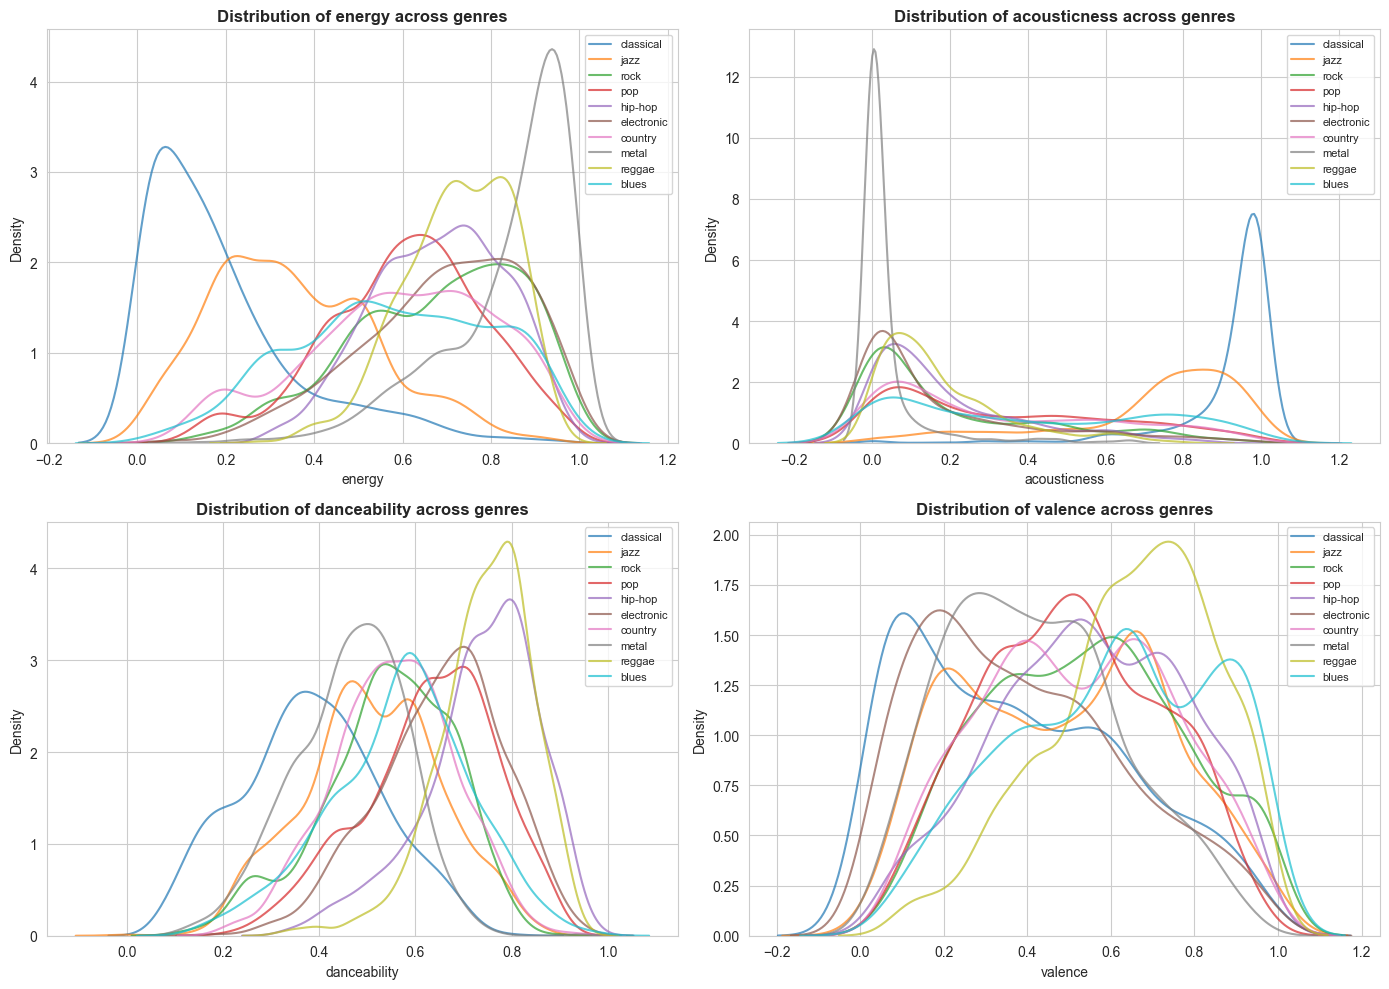

In [ ]:
# KDE plots: density of each genre per feature 
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

features_to_show = ["energy", "acousticness", "danceability", "valence"]

for i, feature in enumerate(features_to_show):
    for genre in SELECTED_GENRES:
        subset = df_subset[df_subset["track_genre"] == genre][feature]
        sns.kdeplot(subset, ax=axes[i], label=genre, alpha=0.7)
    axes[i].set_title(f"Distribution of {feature} across genres", fontweight="bold")
    axes[i].legend(fontsize=8, loc="best")

plt.tight_layout()
plt.savefig("figures/03_kde_by_genre.png", dpi=120, bbox_inches="tight")
plt.show()

Phase 3: Feature Dependencies

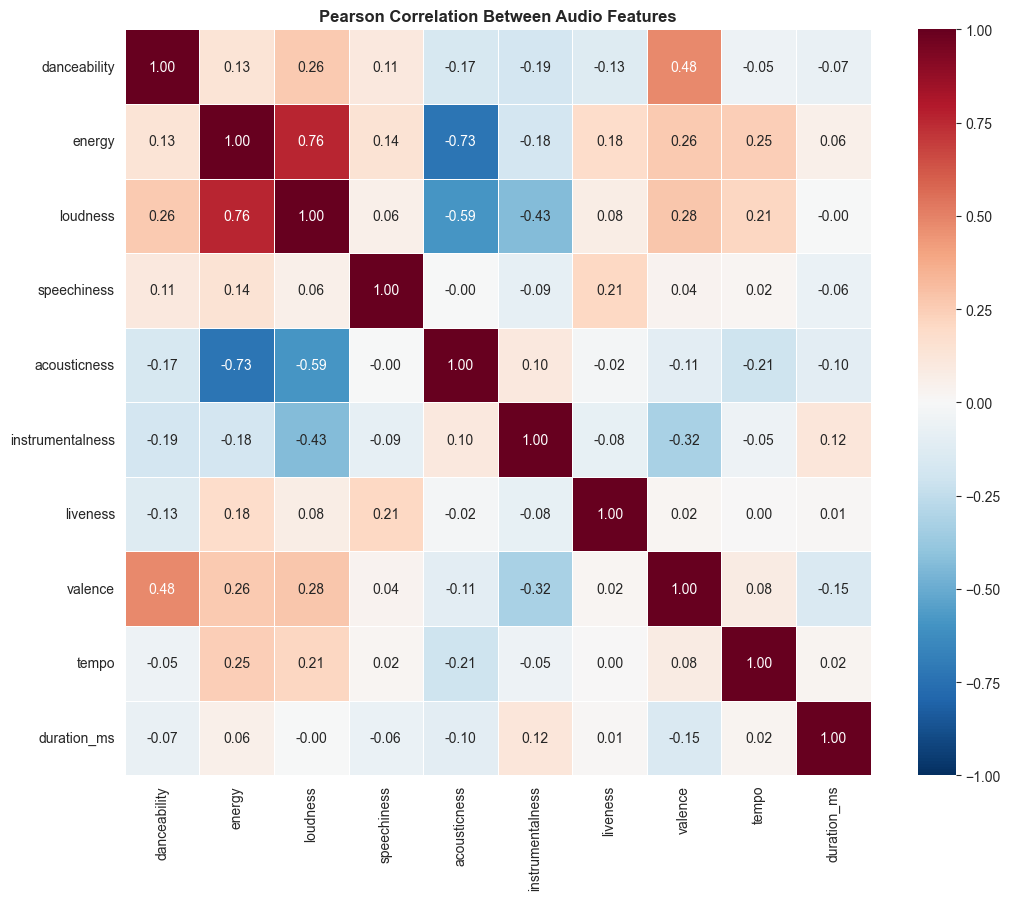

In [ ]:
# Pearson correlation matrix 
pearson_corr = df[AUDIO_FEATURES].corr(method="pearson")

plt.figure(figsize=(11, 9))
sns.heatmap(
    pearson_corr, annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5
)
plt.title("Pearson Correlation Between Audio Features", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/04_pearson_correlation.png", dpi=120, bbox_inches="tight")
plt.show()

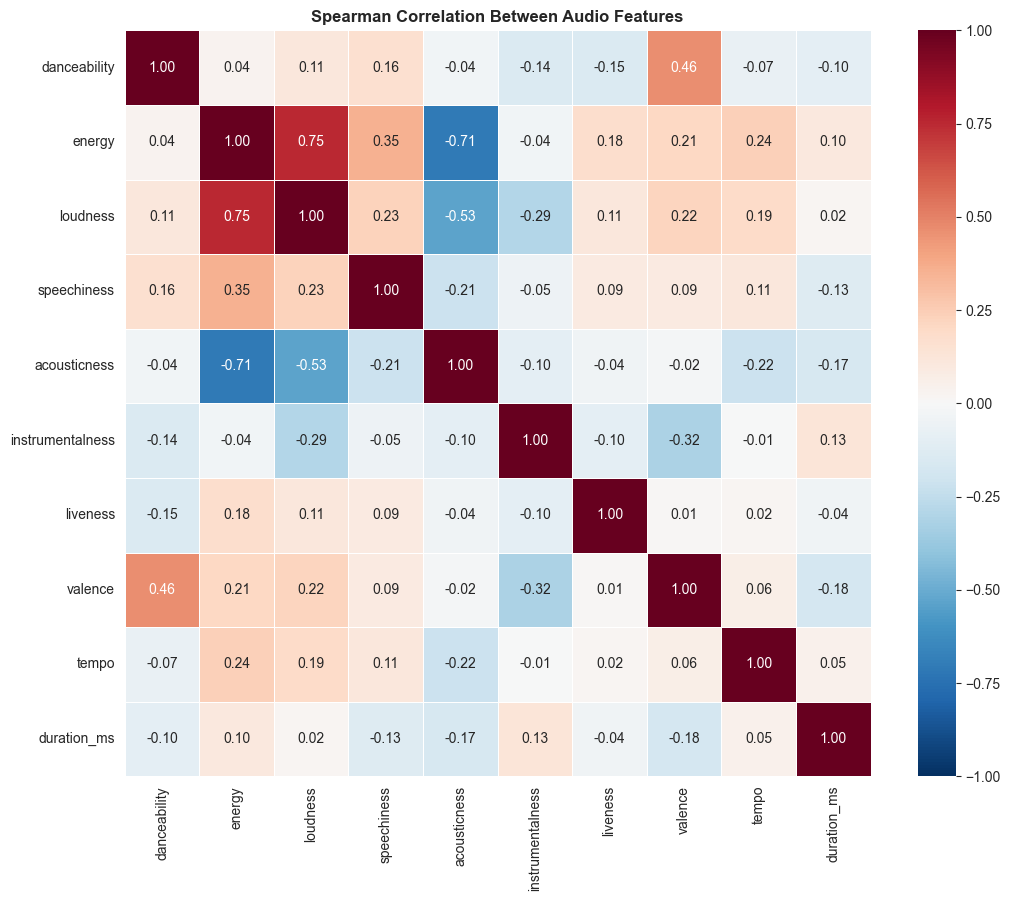

In [ ]:
# Spearman correlation matrix 
spearman_corr = df[AUDIO_FEATURES].corr(method="spearman")

plt.figure(figsize=(11, 9))
sns.heatmap(
    spearman_corr, annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5
)
plt.title("Spearman Correlation Between Audio Features", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/05_spearman_correlation.png", dpi=120, bbox_inches="tight")
plt.show()

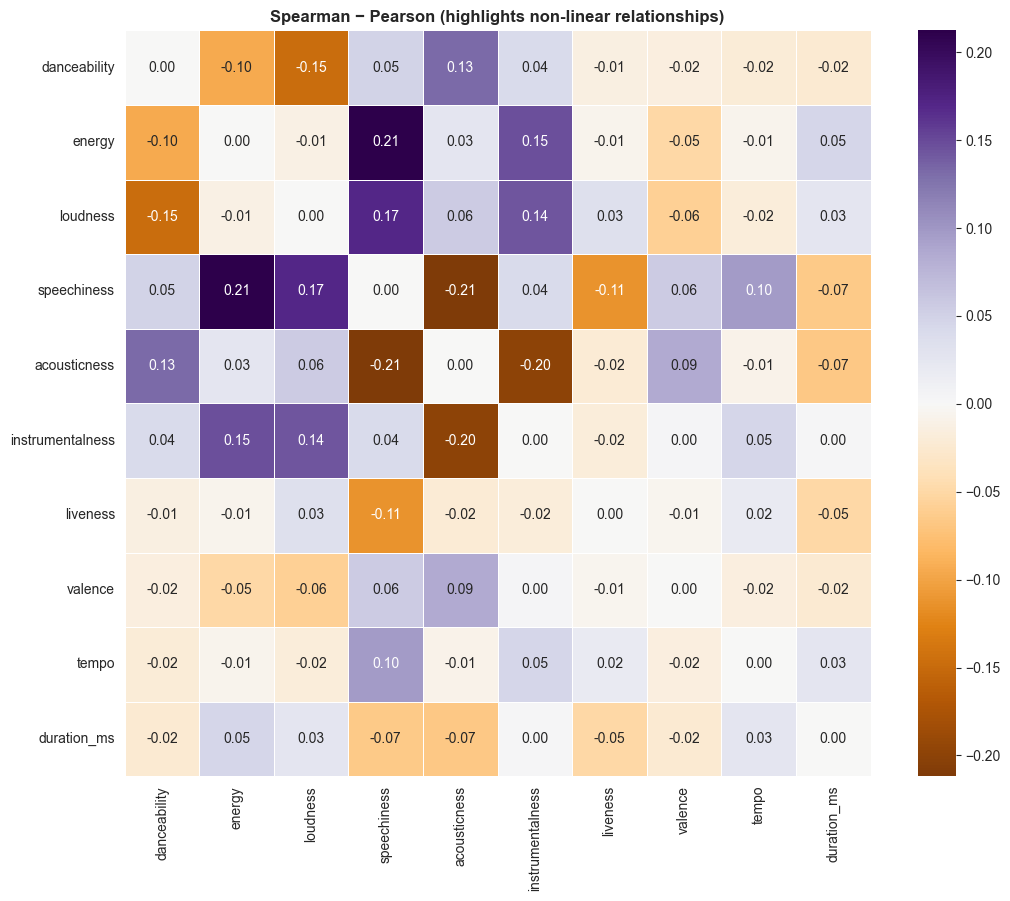

In [7]:
# Difference between Spearman and Pearson highlights non-linear relationships
diff = spearman_corr - pearson_corr

plt.figure(figsize=(11, 9))
sns.heatmap(
    diff, annot=True, fmt=".2f",
    cmap="PuOr", center=0,
    square=True, linewidths=0.5
)
plt.title("Spearman − Pearson (highlights non-linear relationships)", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/06_correlation_difference.png", dpi=120, bbox_inches="tight")
plt.show()

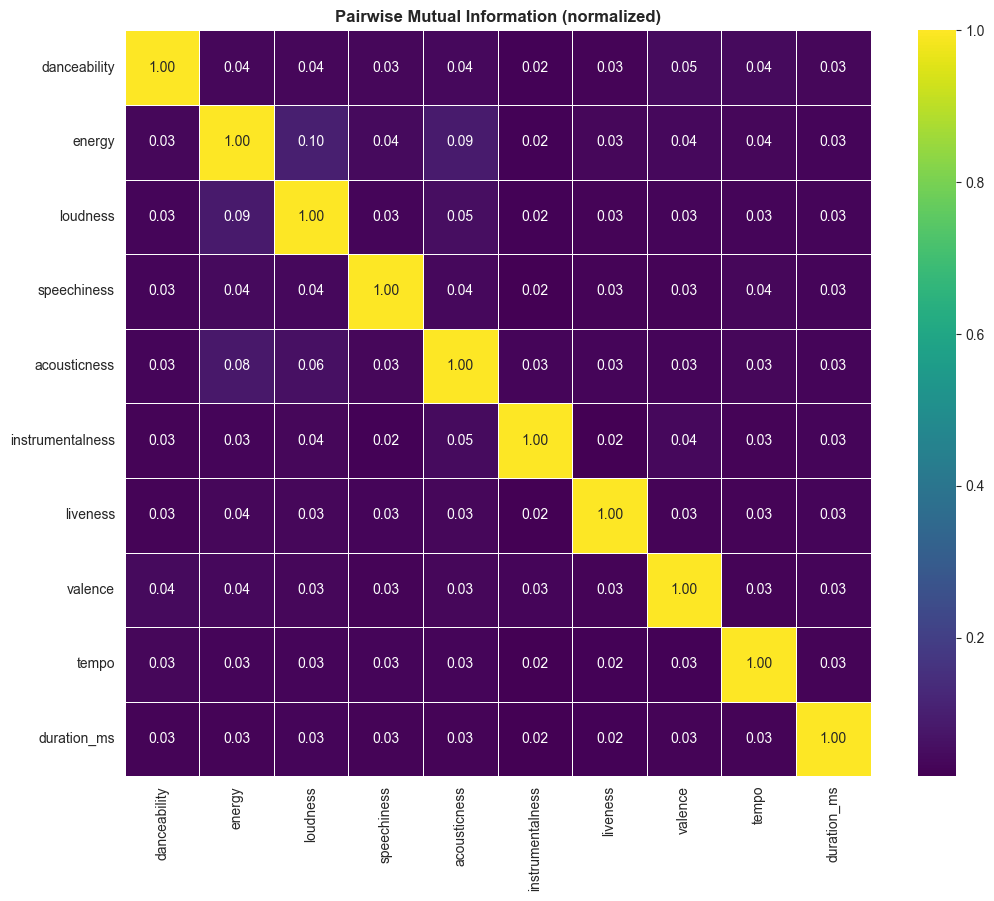

In [ ]:
from sklearn.feature_selection import mutual_info_regression

# Computing pairwise mutual information
n_features = len(AUDIO_FEATURES)
mi_matrix = np.zeros((n_features, n_features))

# Using a sample to speed things up 
sample = df[AUDIO_FEATURES].sample(n=10000, random_state=RANDOM_SEED).values

for i in range(n_features):
    mi = mutual_info_regression(sample, sample[:, i], random_state=RANDOM_SEED)
    mi_matrix[i] = mi

# Normalizing so diagonal = 1 
mi_matrix_normalized = mi_matrix / mi_matrix.diagonal()[:, None]

mi_df = pd.DataFrame(mi_matrix_normalized, index=AUDIO_FEATURES, columns=AUDIO_FEATURES)

plt.figure(figsize=(11, 9))
sns.heatmap(
    mi_df, annot=True, fmt=".2f",
    cmap="viridis",
    square=True, linewidths=0.5
)
plt.title("Pairwise Mutual Information (normalized)", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/07_mutual_information.png", dpi=120, bbox_inches="tight")
plt.show()

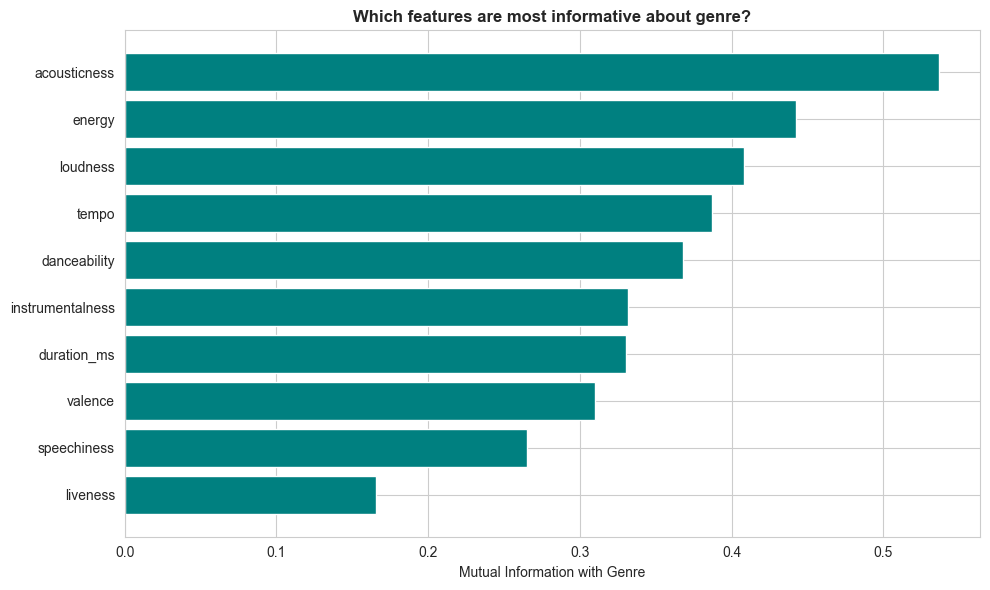

,feature,MI_with_genre
6,liveness,0.165737
3,speechiness,0.265363
7,valence,0.310053
9,duration_ms,0.330653
5,instrumentalness,0.331953
0,danceability,0.367719
8,tempo,0.387241
2,loudness,0.408362
1,energy,0.442123
4,acousticness,0.536847


In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import mutual_info_classif

# Encoding genres as integers
le = LabelEncoder()
genre_encoded = le.fit_transform(df["track_genre"])

# Sample for speed
sample_idx = df.sample(n=20000, random_state=RANDOM_SEED).index
X_sample = df.loc[sample_idx, AUDIO_FEATURES].values
y_sample = genre_encoded[sample_idx]

mi_genre = mutual_info_classif(X_sample, y_sample, random_state=RANDOM_SEED)

mi_genre_df = pd.DataFrame({
    "feature": AUDIO_FEATURES,
    "MI_with_genre": mi_genre
}).sort_values("MI_with_genre", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(mi_genre_df["feature"], mi_genre_df["MI_with_genre"], color="teal")
plt.xlabel("Mutual Information with Genre")
plt.title("Which features are most informative about genre?", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/08_mi_with_genre.png", dpi=120, bbox_inches="tight")
plt.show()

mi_genre_df

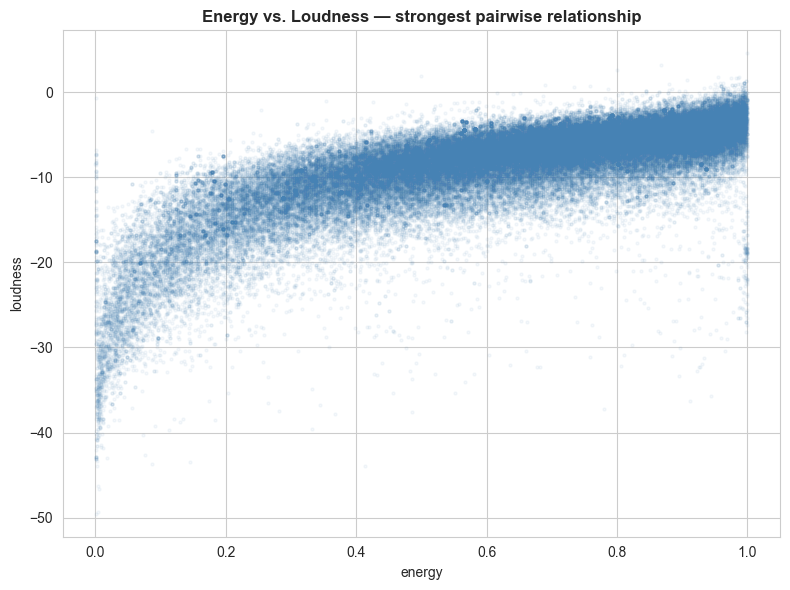

In [10]:
plt.figure(figsize=(8, 6))
plt.scatter(
    df["energy"], df["loudness"],
    alpha=0.05, s=5, color="steelblue"
)
plt.xlabel("energy")
plt.ylabel("loudness")
plt.title("Energy vs. Loudness — strongest pairwise relationship", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/09_energy_vs_loudness.png", dpi=120, bbox_inches="tight")
plt.show()

Phase 4: Latent Structure Discovery

In [ ]:
from sklearn.preprocessing import StandardScaler

# Using  subset from Phase 2 for visualization (10 genres)
# Using full data for PCA fitting
scaler = StandardScaler()
X_full = scaler.fit_transform(df[AUDIO_FEATURES].values)
X_subset = scaler.transform(df_subset[AUDIO_FEATURES].values)

print("Full data shape:", X_full.shape)
print("Subset shape:", X_subset.shape)
print("Mean after scaling:", X_full.mean(axis=0).round(3))
print("Std after scaling:", X_full.std(axis=0).round(3))

Full data shape: (114000, 10)
Subset shape: (10000, 10)
Mean after scaling: [-0.  0. -0. -0.  0.  0. -0. -0. -0.  0.]
Std after scaling: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


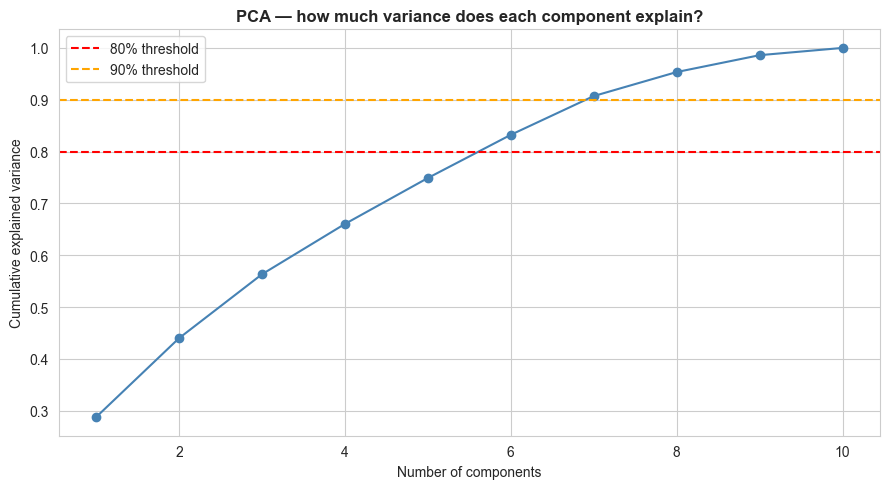

PC1: 0.287 (0.287 cumulative)
PC2: 0.152 (0.440 cumulative)
PC3: 0.123 (0.563 cumulative)
PC4: 0.097 (0.660 cumulative)
PC5: 0.089 (0.749 cumulative)
PC6: 0.083 (0.832 cumulative)
PC7: 0.075 (0.907 cumulative)
PC8: 0.046 (0.953 cumulative)
PC9: 0.033 (0.986 cumulative)
PC10: 0.014 (1.000 cumulative)


In [ ]:
from sklearn.decomposition import PCA

# Fitting PCA with all components first to see explained variance
pca_full = PCA()
pca_full.fit(X_full)

# Plotting cumulative explained variance
plt.figure(figsize=(9, 5))
cumulative_var = np.cumsum(pca_full.explained_variance_ratio_)
plt.plot(range(1, len(cumulative_var) + 1), cumulative_var, marker="o", color="steelblue")
plt.axhline(0.8, color="red", linestyle="--", label="80% threshold")
plt.axhline(0.9, color="orange", linestyle="--", label="90% threshold")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA — how much variance does each component explain?", fontweight="bold")
plt.legend()
plt.tight_layout()
plt.savefig("figures/10_pca_variance.png", dpi=120, bbox_inches="tight")
plt.show()



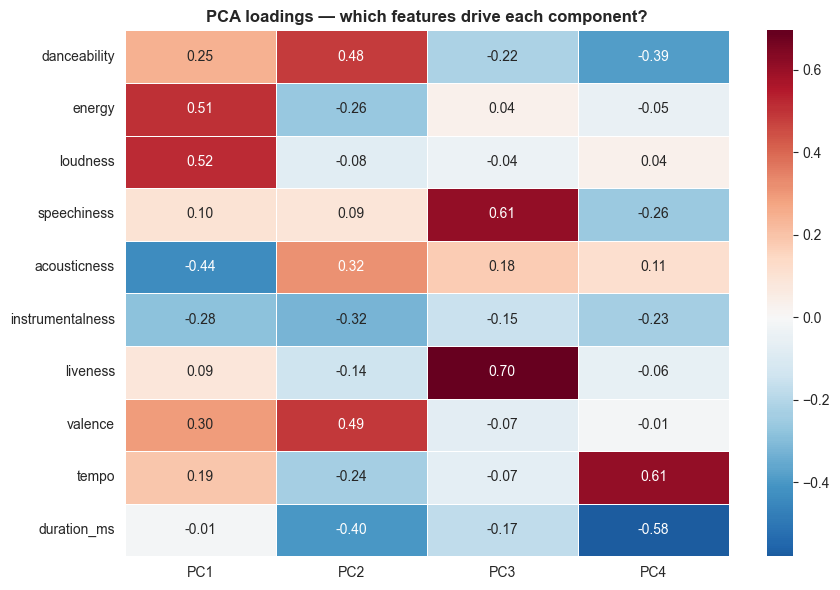

,PC1,PC2,PC3,PC4
danceability,0.246935,0.483658,-0.216952,-0.389189
energy,0.508440,-0.263315,0.037330,-0.054701
loudness,0.516758,-0.077836,-0.039154,0.037474
speechiness,0.101136,0.091312,0.609109,-0.256794
acousticness,-0.438282,0.315509,0.176575,0.114472
instrumentalness,-0.283429,-0.321246,-0.153506,-0.232356
liveness,0.085004,-0.143973,0.695817,-0.056957
valence,0.296318,0.487675,-0.072566,-0.012406
tempo,0.188653,-0.240289,-0.068904,0.610368
duration_ms,-0.014177,-0.404111,-0.173418,-0.578924


In [ ]:
# how much each original feature contributes to each PC
loadings = pd.DataFrame(
    pca_full.components_[:4].T,  # First 4 PCs
    columns=[f"PC{i+1}" for i in range(4)],
    index=AUDIO_FEATURES
)

plt.figure(figsize=(9, 6))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5)
plt.title("PCA loadings — which features drive each component?", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/11_pca_loadings.png", dpi=120, bbox_inches="tight")
plt.show()

loadings

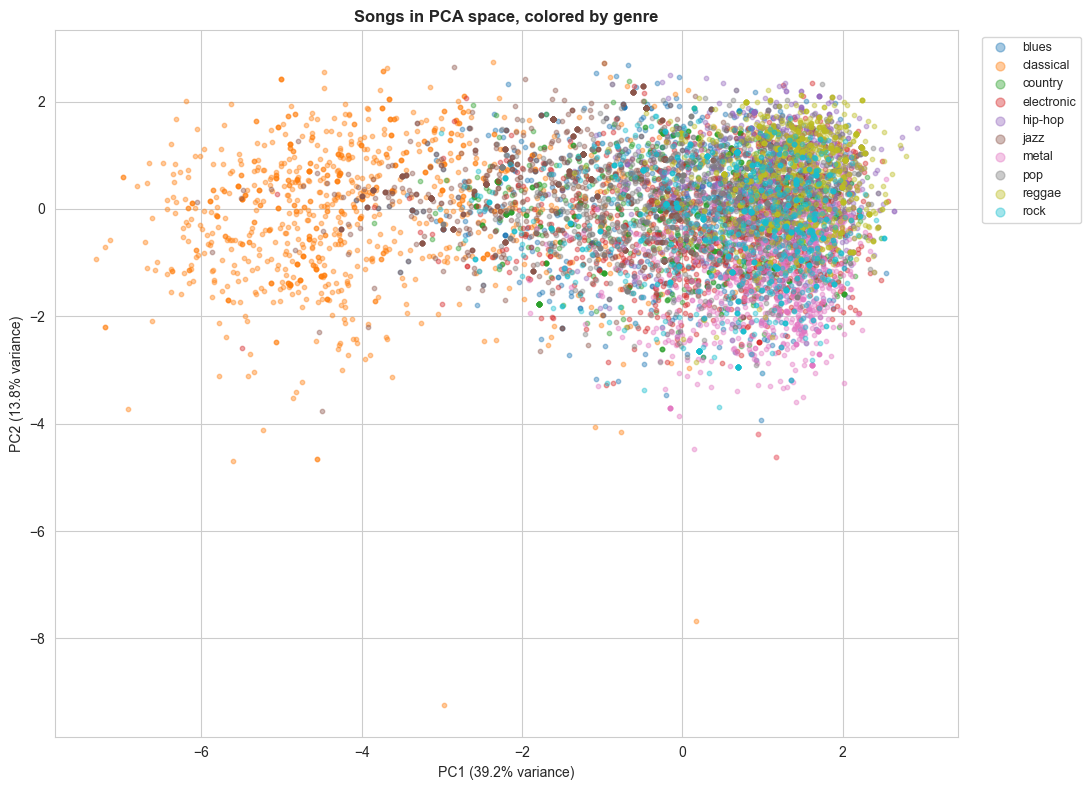

In [ ]:
# Projecting subset to 2D for visualization
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_subset)

plt.figure(figsize=(11, 8))
genres = df_subset["track_genre"].values
unique_genres = sorted(set(genres))
palette = sns.color_palette("tab10", n_colors=len(unique_genres))

for genre, color in zip(unique_genres, palette):
    mask = genres == genre
    plt.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        alpha=0.4, s=10, color=color, label=genre
    )

plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]:.1%} variance)")
plt.title("Songs in PCA space, colored by genre", fontweight="bold")
plt.legend(markerscale=2, fontsize=9, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("figures/12_pca_2d_by_genre.png", dpi=120, bbox_inches="tight")
plt.show()

Running t-SNE (this takes 1-2 minutes)...
Done.


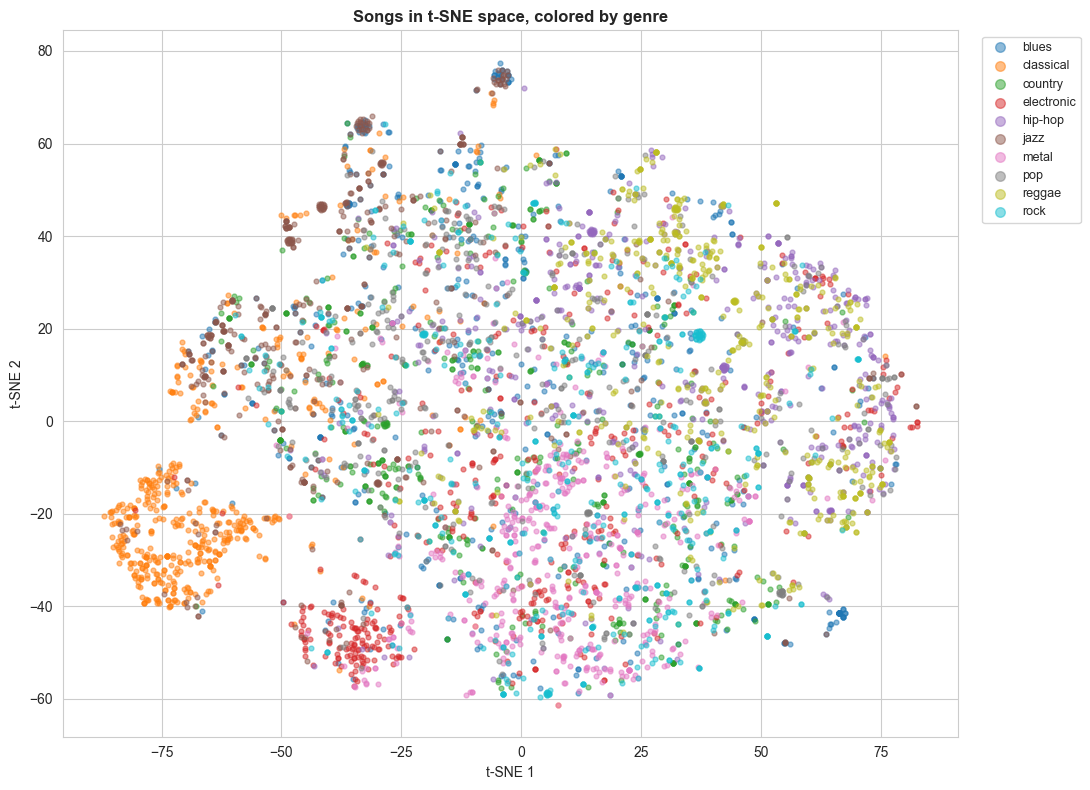

In [ ]:
from sklearn.manifold import TSNE

# Sample for t-SNE 
sample_size = 5000
sample_idx = df_subset.sample(n=sample_size, random_state=RANDOM_SEED).index
X_sample_tsne = scaler.transform(df_subset.loc[sample_idx, AUDIO_FEATURES].values)
genres_sample = df_subset.loc[sample_idx, "track_genre"].values

print("Running t-SNE (this takes 1-2 minutes)...")
tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_SEED, max_iter=1000)
X_tsne = tsne.fit_transform(X_sample_tsne)
print("Done.")

plt.figure(figsize=(11, 8))
for genre, color in zip(unique_genres, palette):
    mask = genres_sample == genre
    plt.scatter(
        X_tsne[mask, 0], X_tsne[mask, 1],
        alpha=0.5, s=12, color=color, label=genre
    )

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Songs in t-SNE space, colored by genre", fontweight="bold")
plt.legend(markerscale=2, fontsize=9, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("figures/13_tsne_by_genre.png", dpi=120, bbox_inches="tight")
plt.show()

Running UMAP...


c:\Users\sride\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Done.


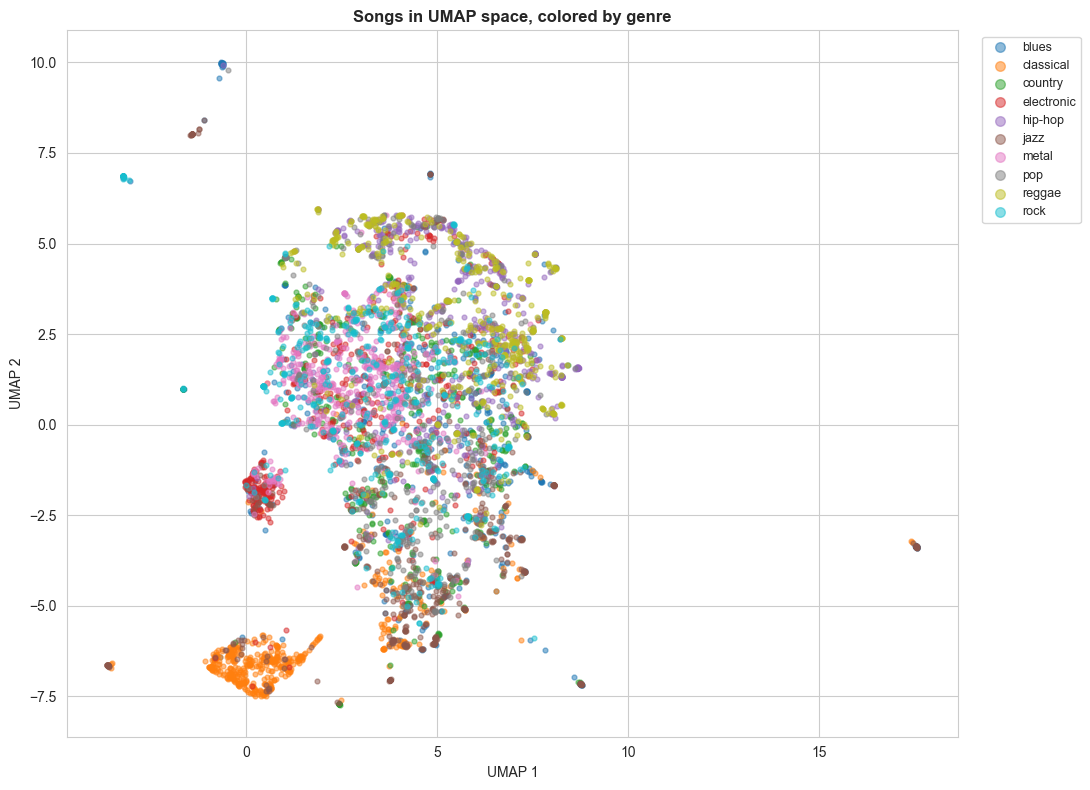

In [19]:
import umap

print("Running UMAP...")
reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=RANDOM_SEED)
X_umap = reducer.fit_transform(X_sample_tsne)
print("Done.")

plt.figure(figsize=(11, 8))
for genre, color in zip(unique_genres, palette):
    mask = genres_sample == genre
    plt.scatter(
        X_umap[mask, 0], X_umap[mask, 1],
        alpha=0.5, s=12, color=color, label=genre
    )

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("Songs in UMAP space, colored by genre", fontweight="bold")
plt.legend(markerscale=2, fontsize=9, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("figures/14_umap_by_genre.png", dpi=120, bbox_inches="tight")
plt.show()

n=2: BIC=346081
n=3: BIC=332750
n=4: BIC=294735
n=5: BIC=279450
n=6: BIC=269701
n=7: BIC=265351
n=8: BIC=260217
n=9: BIC=254095
n=10: BIC=251320
n=11: BIC=250344
n=12: BIC=246508
n=13: BIC=242652
n=14: BIC=240775
n=15: BIC=236898


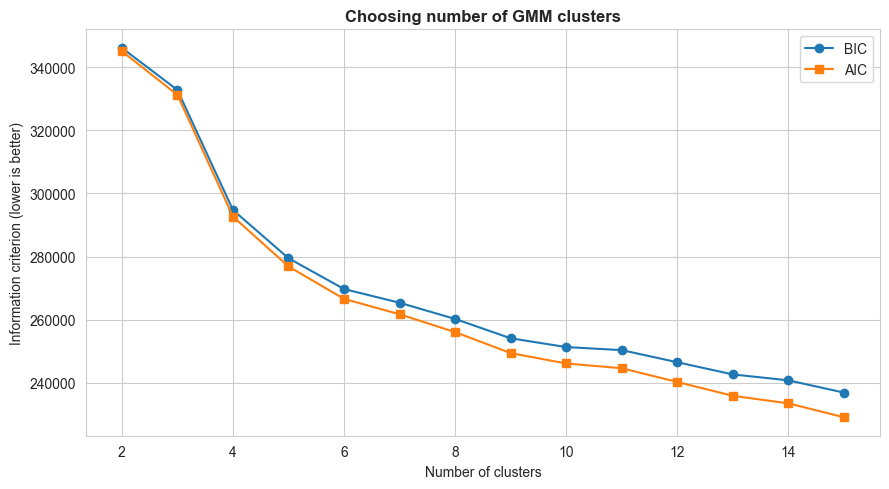

In [20]:
from sklearn.mixture import GaussianMixture

# Use a sample for speed
X_for_gmm = scaler.transform(df.sample(n=20000, random_state=RANDOM_SEED)[AUDIO_FEATURES].values)

# Try different numbers of clusters
n_components_range = range(2, 16)
bic_scores = []
aic_scores = []

for n in n_components_range:
    gmm = GaussianMixture(n_components=n, covariance_type="full", random_state=RANDOM_SEED, n_init=3)
    gmm.fit(X_for_gmm)
    bic_scores.append(gmm.bic(X_for_gmm))
    aic_scores.append(gmm.aic(X_for_gmm))
    print(f"n={n}: BIC={bic_scores[-1]:.0f}")

plt.figure(figsize=(9, 5))
plt.plot(n_components_range, bic_scores, marker="o", label="BIC")
plt.plot(n_components_range, aic_scores, marker="s", label="AIC")
plt.xlabel("Number of clusters")
plt.ylabel("Information criterion (lower is better)")
plt.title("Choosing number of GMM clusters", fontweight="bold")
plt.legend()
plt.tight_layout()
plt.savefig("figures/15_gmm_bic.png", dpi=120, bbox_inches="tight")
plt.show()

In [ ]:
# Picking optimal k from the plot above 
OPTIMAL_K = 6  # change this based on your BIC plot

gmm_final = GaussianMixture(
    n_components=OPTIMAL_K,
    covariance_type="full",
    random_state=RANDOM_SEED,
    n_init=5
)
gmm_final.fit(X_full)

# Assign each song to its cluster
cluster_labels = gmm_final.predict(X_full)
df["gmm_cluster"] = cluster_labels

print(f"Cluster sizes:")
print(pd.Series(cluster_labels).value_counts().sort_index())

Cluster sizes:
0     9345
1    13968
2    17521
3    22051
4    37784
5    13331
Name: count, dtype: int64


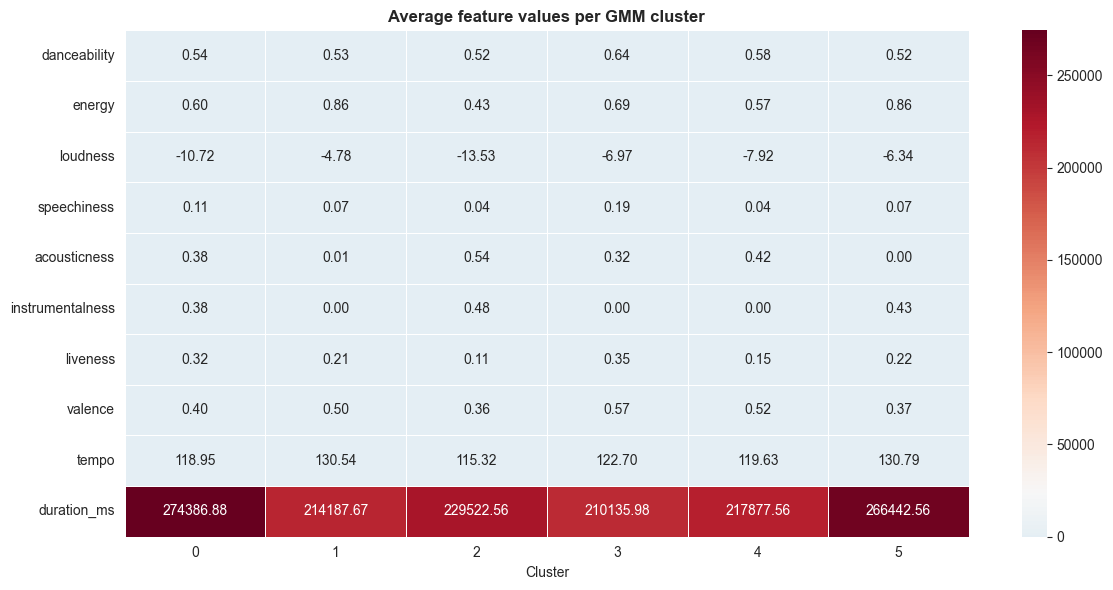

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
gmm_cluster,,,,,,,,,,
0,0.538437,0.597774,-10.718078,0.112164,0.382886,0.383316,0.324965,0.401700,118.954714,274386.879722
1,0.532033,0.863540,-4.783871,0.071110,0.009892,0.000318,0.214758,0.496342,130.542504,214187.673611
2,0.523368,0.429632,-13.532647,0.043963,0.535278,0.484712,0.111854,0.357830,115.320060,229522.558301
3,0.637129,0.687359,-6.972384,0.193944,0.319942,0.000061,0.350359,0.573429,122.696676,210135.979275
4,0.581560,0.565143,-7.916265,0.041445,0.415996,0.000102,0.152351,0.517351,119.631841,217877.558093
5,0.522028,0.857522,-6.344479,0.074713,0.002391,0.427973,0.215026,0.367202,130.787437,266442.559523


In [ ]:
# Mean feature values per cluster(what makes each cluster distinct?)
cluster_profiles = df.groupby("gmm_cluster")[AUDIO_FEATURES].mean()

plt.figure(figsize=(12, 6))
sns.heatmap(
    cluster_profiles.T, annot=True, fmt=".2f",
    cmap="RdBu_r", center=cluster_profiles.values.mean(),
    linewidths=0.5
)
plt.title("Average feature values per GMM cluster", fontweight="bold")
plt.xlabel("Cluster")
plt.tight_layout()
plt.savefig("figures/16_gmm_cluster_profiles.png", dpi=120, bbox_inches="tight")
plt.show()

cluster_profiles

In [ ]:
# do GMM clusters align with actual genres?
crosstab = pd.crosstab(df["gmm_cluster"], df["track_genre"])

# Showing top 5 genres per cluster
for cluster_id in range(OPTIMAL_K):
    top_genres = crosstab.loc[cluster_id].sort_values(ascending=False).head(5)
    print(f"\nCluster {cluster_id} — top genres:")
    print(top_genres)


Cluster 0 — top genres:
track_genre
sleep      558
study      440
iranian    288
idm        233
happy      229
Name: 0, dtype: int64

Cluster 1 — top genres:
track_genre
metalcore      621
grunge         492
heavy-metal    465
punk-rock      459
punk           458
Name: 1, dtype: int64

Cluster 2 — top genres:
track_genre
ambient      796
new-age      715
classical    687
piano        583
guitar       568
Name: 2, dtype: int64

Cluster 3 — top genres:
track_genre
comedy       926
j-dance      747
dancehall    683
pagode       630
sertanejo    596
Name: 3, dtype: int64

Cluster 4 — top genres:
track_genre
mandopop      853
cantopop      782
honky-tonk    743
salsa         728
acoustic      720
Name: 4, dtype: int64

Cluster 5 — top genres:
track_genre
grindcore        823
black-metal      736
death-metal      677
drum-and-bass    552
breakbeat        525
Name: 5, dtype: int64


Phase 5: VAE Training

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


torch.manual_seed(RANDOM_SEED)

Using device: cpu


In [ ]:
# Convert to PyTorch tensor
X_tensor = torch.FloatTensor(X_full)

# Train/validation split (80/20)
n_samples = len(X_tensor)
n_train = int(0.8 * n_samples)
perm = torch.randperm(n_samples)
train_idx, val_idx = perm[:n_train], perm[n_train:]

X_train = X_tensor[train_idx]
X_val = X_tensor[val_idx]

print(f"Train size: {len(X_train)}, Validation size: {len(X_val)}")

# Creating data loaders
BATCH_SIZE = 256
train_loader = DataLoader(TensorDataset(X_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val), batch_size=BATCH_SIZE, shuffle=False)

Train size: 91200, Validation size: 22800


In [ ]:
class VAE(nn.Module):
    def __init__(self, input_dim=10, hidden_dim=64, latent_dim=3):
        """
        input_dim: number of features (10 audio features)
        hidden_dim: size of hidden layers (64 is plenty for this problem)
        latent_dim: size of latent space (3 is small enough to visualize,
                    large enough to capture structure)
        """
        super().__init__()

        
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)

        # === Decoder: z -> hidden -> reconstruction ===
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        """The reparameterization trick: z = mu + sigma * epsilon"""
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_reconstructed = self.decode(z)
        return x_reconstructed, mu, logvar

In [ ]:
def vae_loss(x, x_reconstructed, mu, logvar, beta=1.0):
   
    # Reconstruction loss 
    recon_loss = F.mse_loss(x_reconstructed, x, reduction="sum")

    # KL divergence: forces latent distribution toward N(0, 1)
    # Closed-form formula for KL(N(mu, sigma^2) || N(0, 1))
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    return recon_loss + beta * kl_loss, recon_loss, kl_loss

In [ ]:
# Hyperparameters
LATENT_DIM = 3
HIDDEN_DIM = 64
LEARNING_RATE = 1e-3
N_EPOCHS = 50
BETA = 1.0

# Initializing model and optimizer
model = VAE(input_dim=10, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Tracking losses
train_losses, val_losses = [], []
train_recon, train_kl = [], []


for epoch in range(N_EPOCHS):
    #Training 
    model.train()
    epoch_loss, epoch_recon, epoch_kl = 0, 0, 0
    for (x_batch,) in train_loader:
        x_batch = x_batch.to(device)
        optimizer.zero_grad()

        x_recon, mu, logvar = model(x_batch)
        loss, recon, kl = vae_loss(x_batch, x_recon, mu, logvar, beta=BETA)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_recon += recon.item()
        epoch_kl += kl.item()

    avg_loss = epoch_loss / len(X_train)
    avg_recon = epoch_recon / len(X_train)
    avg_kl = epoch_kl / len(X_train)
    train_losses.append(avg_loss)
    train_recon.append(avg_recon)
    train_kl.append(avg_kl)

    # Validation 
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for (x_batch,) in val_loader:
            x_batch = x_batch.to(device)
            x_recon, mu, logvar = model(x_batch)
            loss, _, _ = vae_loss(x_batch, x_recon, mu, logvar, beta=BETA)
            val_loss += loss.item()
    val_loss /= len(X_val)
    val_losses.append(val_loss)

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:3d} | "
              f"Train Loss: {avg_loss:.4f} | "
              f"Recon: {avg_recon:.4f} | "
              f"KL: {avg_kl:.4f} | "
              f"Val Loss: {val_loss:.4f}")



Training VAE...
Epoch   5 | Train Loss: 6.2256 | Recon: 3.8432 | KL: 2.3825 | Val Loss: 6.2016
Epoch  10 | Train Loss: 6.1504 | Recon: 3.7018 | KL: 2.4486 | Val Loss: 6.1176
Epoch  15 | Train Loss: 6.1100 | Recon: 3.6378 | KL: 2.4722 | Val Loss: 6.1282
Epoch  20 | Train Loss: 6.0763 | Recon: 3.5799 | KL: 2.4964 | Val Loss: 6.0708
Epoch  25 | Train Loss: 6.0642 | Recon: 3.5403 | KL: 2.5239 | Val Loss: 6.0679
Epoch  30 | Train Loss: 6.0505 | Recon: 3.5124 | KL: 2.5382 | Val Loss: 6.0305
Epoch  35 | Train Loss: 6.0427 | Recon: 3.4881 | KL: 2.5545 | Val Loss: 6.0328
Epoch  40 | Train Loss: 6.0279 | Recon: 3.4687 | KL: 2.5592 | Val Loss: 6.0303
Epoch  45 | Train Loss: 6.0159 | Recon: 3.4418 | KL: 2.5740 | Val Loss: 6.0006
Epoch  50 | Train Loss: 6.0130 | Recon: 3.4349 | KL: 2.5781 | Val Loss: 5.9834
Training complete.


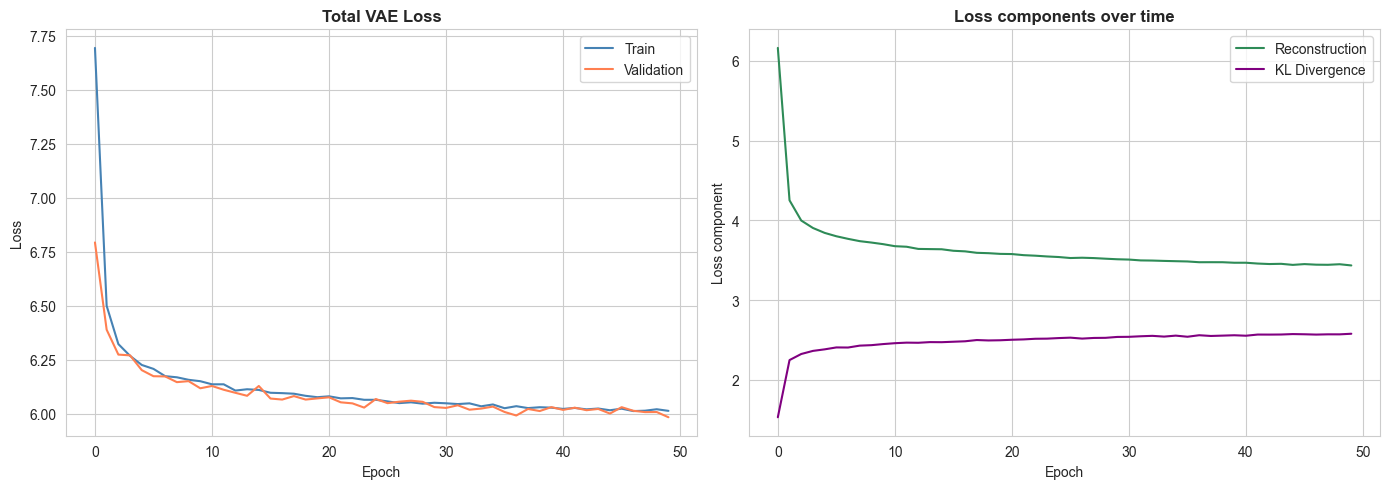

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_losses, label="Train", color="steelblue")
axes[0].plot(val_losses, label="Validation", color="coral")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Total VAE Loss", fontweight="bold")
axes[0].legend()

axes[1].plot(train_recon, label="Reconstruction", color="seagreen")
axes[1].plot(train_kl, label="KL Divergence", color="purple")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss component")
axes[1].set_title("Loss components over time", fontweight="bold")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/17_vae_training.png", dpi=120, bbox_inches="tight")
plt.show()

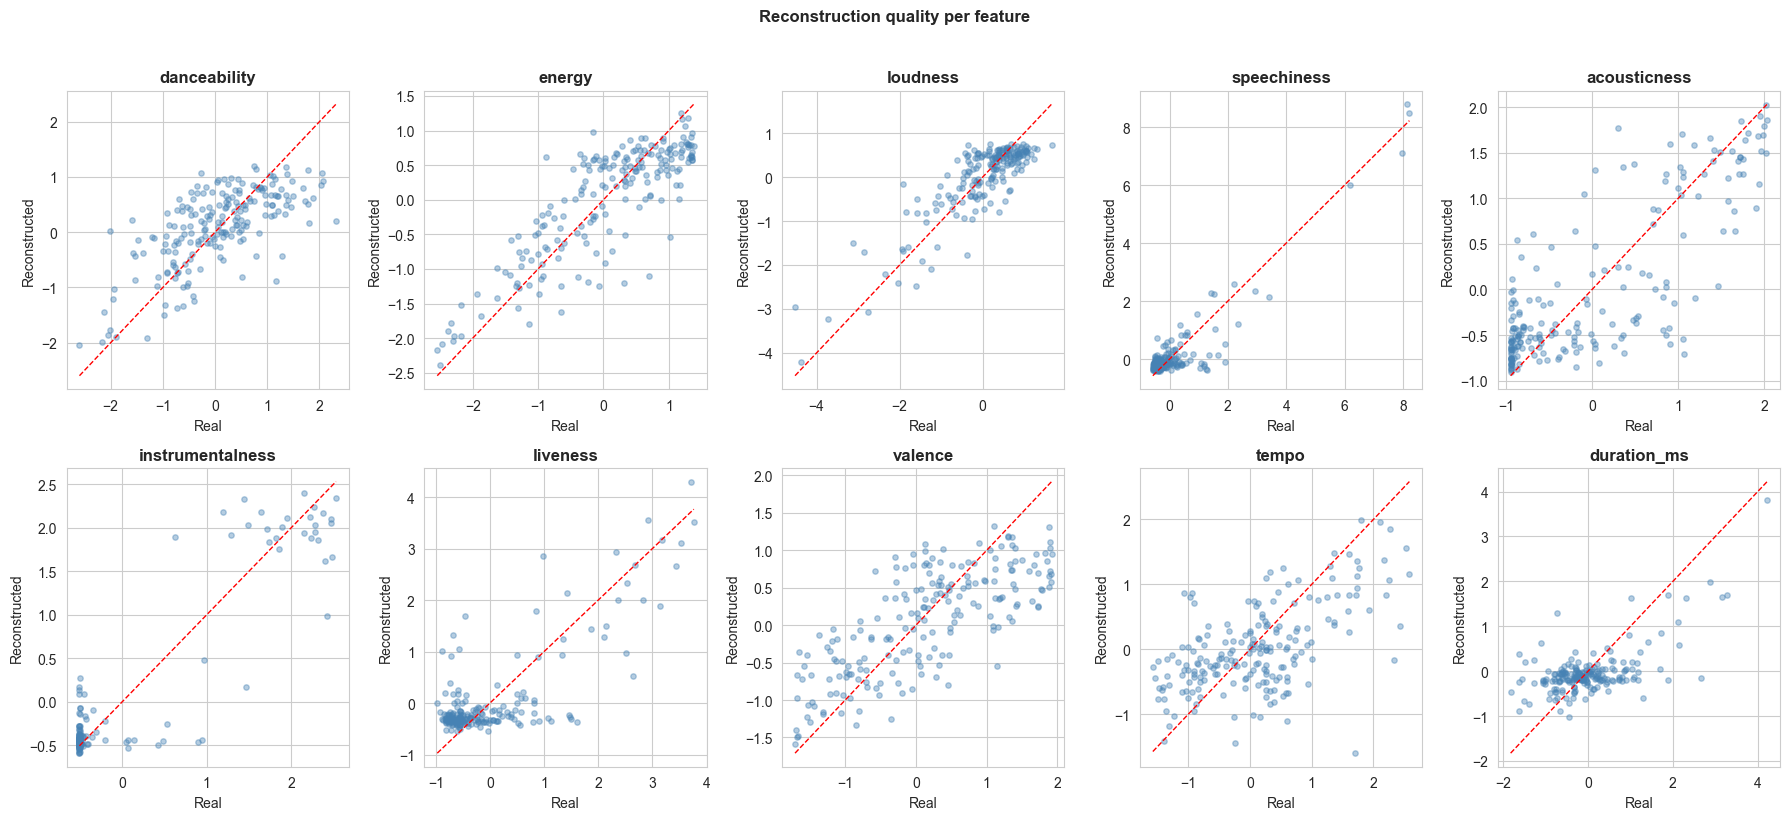

In [ ]:
model.eval()
with torch.no_grad():
    # Picking a small batch of validation songs
    sample = X_val[:200].to(device)
    sample_recon, _, _ = model(sample)
    sample = sample.cpu().numpy()
    sample_recon = sample_recon.cpu().numpy()

# Plotting real vs reconstructed for each feature
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()
for i, feature in enumerate(AUDIO_FEATURES):
    axes[i].scatter(sample[:, i], sample_recon[:, i], alpha=0.4, s=15, color="steelblue")
    lo, hi = sample[:, i].min(), sample[:, i].max()
    axes[i].plot([lo, hi], [lo, hi], "r--", linewidth=1)  # identity line
    axes[i].set_title(feature, fontweight="bold")
    axes[i].set_xlabel("Real")
    axes[i].set_ylabel("Reconstructed")

plt.suptitle("Reconstruction quality per feature", fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("figures/18_vae_reconstructions.png", dpi=120, bbox_inches="tight")
plt.show()

In [32]:
model.eval()
with torch.no_grad():
    X_all = torch.FloatTensor(X_full).to(device)
    mu_all, logvar_all = model.encode(X_all)
    Z = mu_all.cpu().numpy()  # use mean as deterministic latent representation

print(f"Latent representation shape: {Z.shape}")
df["z1"] = Z[:, 0]
df["z2"] = Z[:, 1]
df["z3"] = Z[:, 2]

Latent representation shape: (114000, 3)


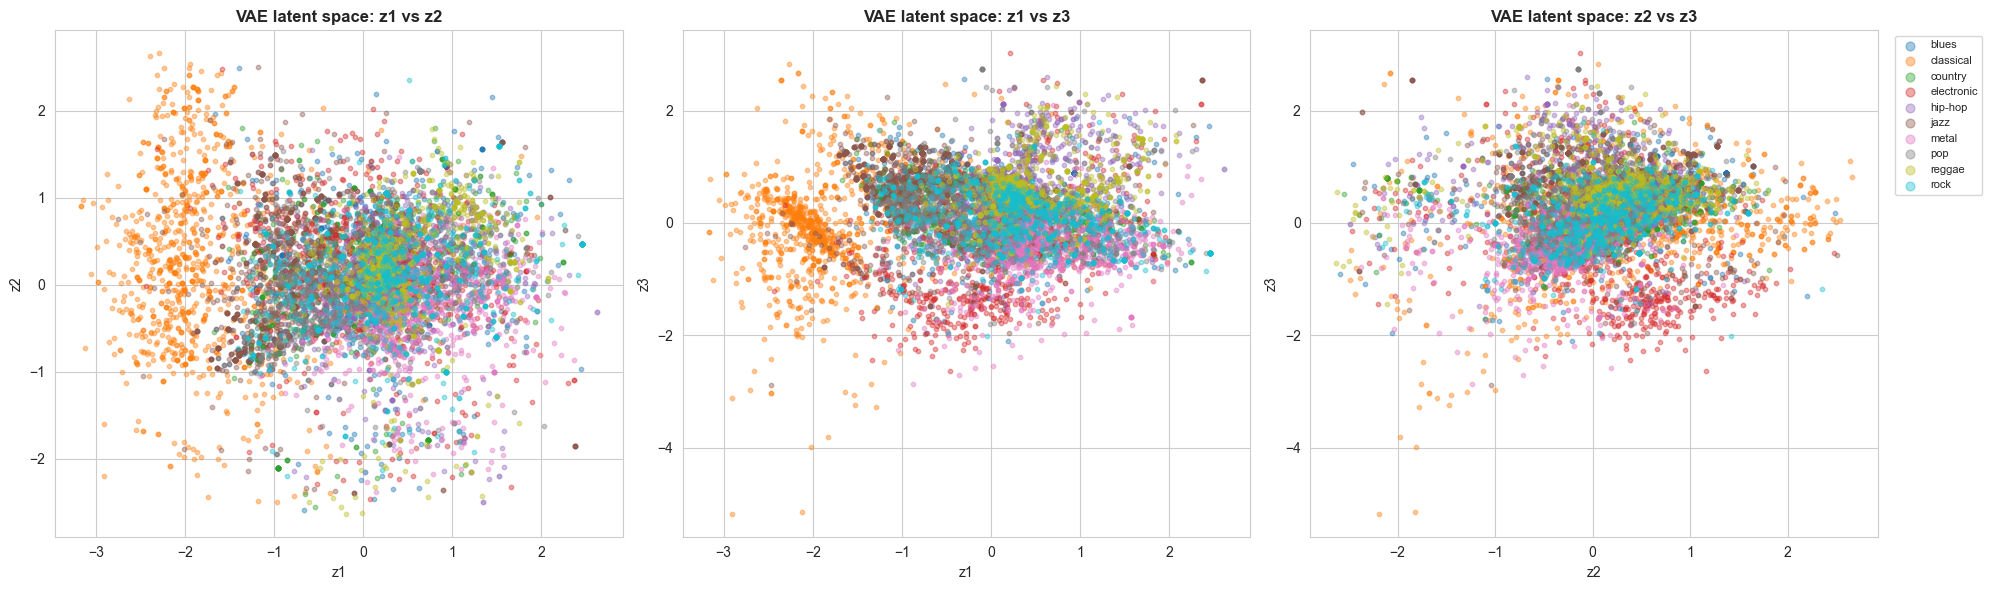

In [ ]:
# Using the same 10 genres from before for visual clarity
df_subset_with_z = df[df["track_genre"].isin(SELECTED_GENRES)]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

pairs = [(0, 1), (0, 2), (1, 2)]
labels = [("z1", "z2"), ("z1", "z3"), ("z2", "z3")]

for ax, (i, j), (xlabel, ylabel) in zip(axes, pairs, labels):
    for genre, color in zip(unique_genres, palette):
        sub = df_subset_with_z[df_subset_with_z["track_genre"] == genre]
        ax.scatter(sub[xlabel], sub[ylabel], alpha=0.4, s=10, color=color, label=genre)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(f"VAE latent space: {xlabel} vs {ylabel}", fontweight="bold")

axes[-1].legend(markerscale=2, fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("figures/19_vae_latent_space.png", dpi=120, bbox_inches="tight")
plt.show()

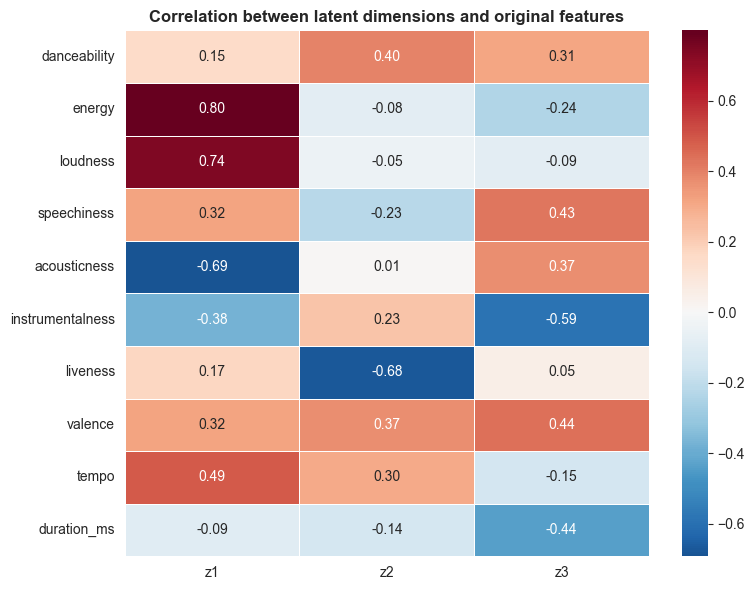

,z1,z2,z3
danceability,0.148,0.395,0.313
energy,0.799,-0.081,-0.238
loudness,0.744,-0.048,-0.086
speechiness,0.320,-0.225,0.430
acousticness,-0.692,0.010,0.369
instrumentalness,-0.375,0.225,-0.589
liveness,0.172,-0.679,0.049
valence,0.320,0.370,0.442
tempo,0.489,0.301,-0.149
duration_ms,-0.093,-0.143,-0.437


In [ ]:
# For each latent dim, finding which feature it's most correlated with
from scipy.stats import pearsonr

latent_interpretation = pd.DataFrame(index=AUDIO_FEATURES, columns=["z1", "z2", "z3"])

for feat in AUDIO_FEATURES:
    for k, z_name in enumerate(["z1", "z2", "z3"]):
        r, _ = pearsonr(df[feat], df[z_name])
        latent_interpretation.loc[feat, z_name] = round(r, 3)

latent_interpretation = latent_interpretation.astype(float)

plt.figure(figsize=(8, 6))
sns.heatmap(latent_interpretation, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5)
plt.title("Correlation between latent dimensions and original features", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/20_latent_interpretation.png", dpi=120, bbox_inches="tight")
plt.show()

latent_interpretation

In [35]:
torch.save(model.state_dict(), "vae_model.pth")
print("Model saved to vae_model.pth")

Model saved to vae_model.pth


Phase 6: Synthetic Data Generation & Validation

In [ ]:
model.eval()

N_SYNTHETIC = 10000  # number of synthetic songs to generate

with torch.no_grad():
    # Sample from standard normal in latent space
    z_random = torch.randn(N_SYNTHETIC, LATENT_DIM).to(device)
    # Decoding to song-feature space
    synthetic_scaled = model.decode(z_random).cpu().numpy()

# Reversing the standardization to get original feature scales back
synthetic_songs = scaler.inverse_transform(synthetic_scaled)

# Wrapping as DataFrame
synthetic_df = pd.DataFrame(synthetic_songs, columns=AUDIO_FEATURES)

synthetic_df.head()

Generated 10000 synthetic songs.

First 5 synthetic songs:


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,0.503305,0.778506,-5.951079,0.076103,0.178351,0.044238,0.156175,0.644826,172.929382,212421.203125
1,0.822723,0.637167,-7.573044,0.264922,0.235024,0.034164,0.126997,0.687379,120.586594,185949.343750
2,0.734824,0.710599,-6.166283,0.131596,0.207314,-0.005662,0.166429,0.671349,101.280464,210832.625000
3,0.752159,0.760452,-5.639509,0.102214,0.177270,0.015278,0.152970,0.768450,118.608521,202893.343750
4,0.362930,0.071125,-27.296089,0.059372,0.938554,0.511550,0.120349,0.287083,140.659256,120914.640625


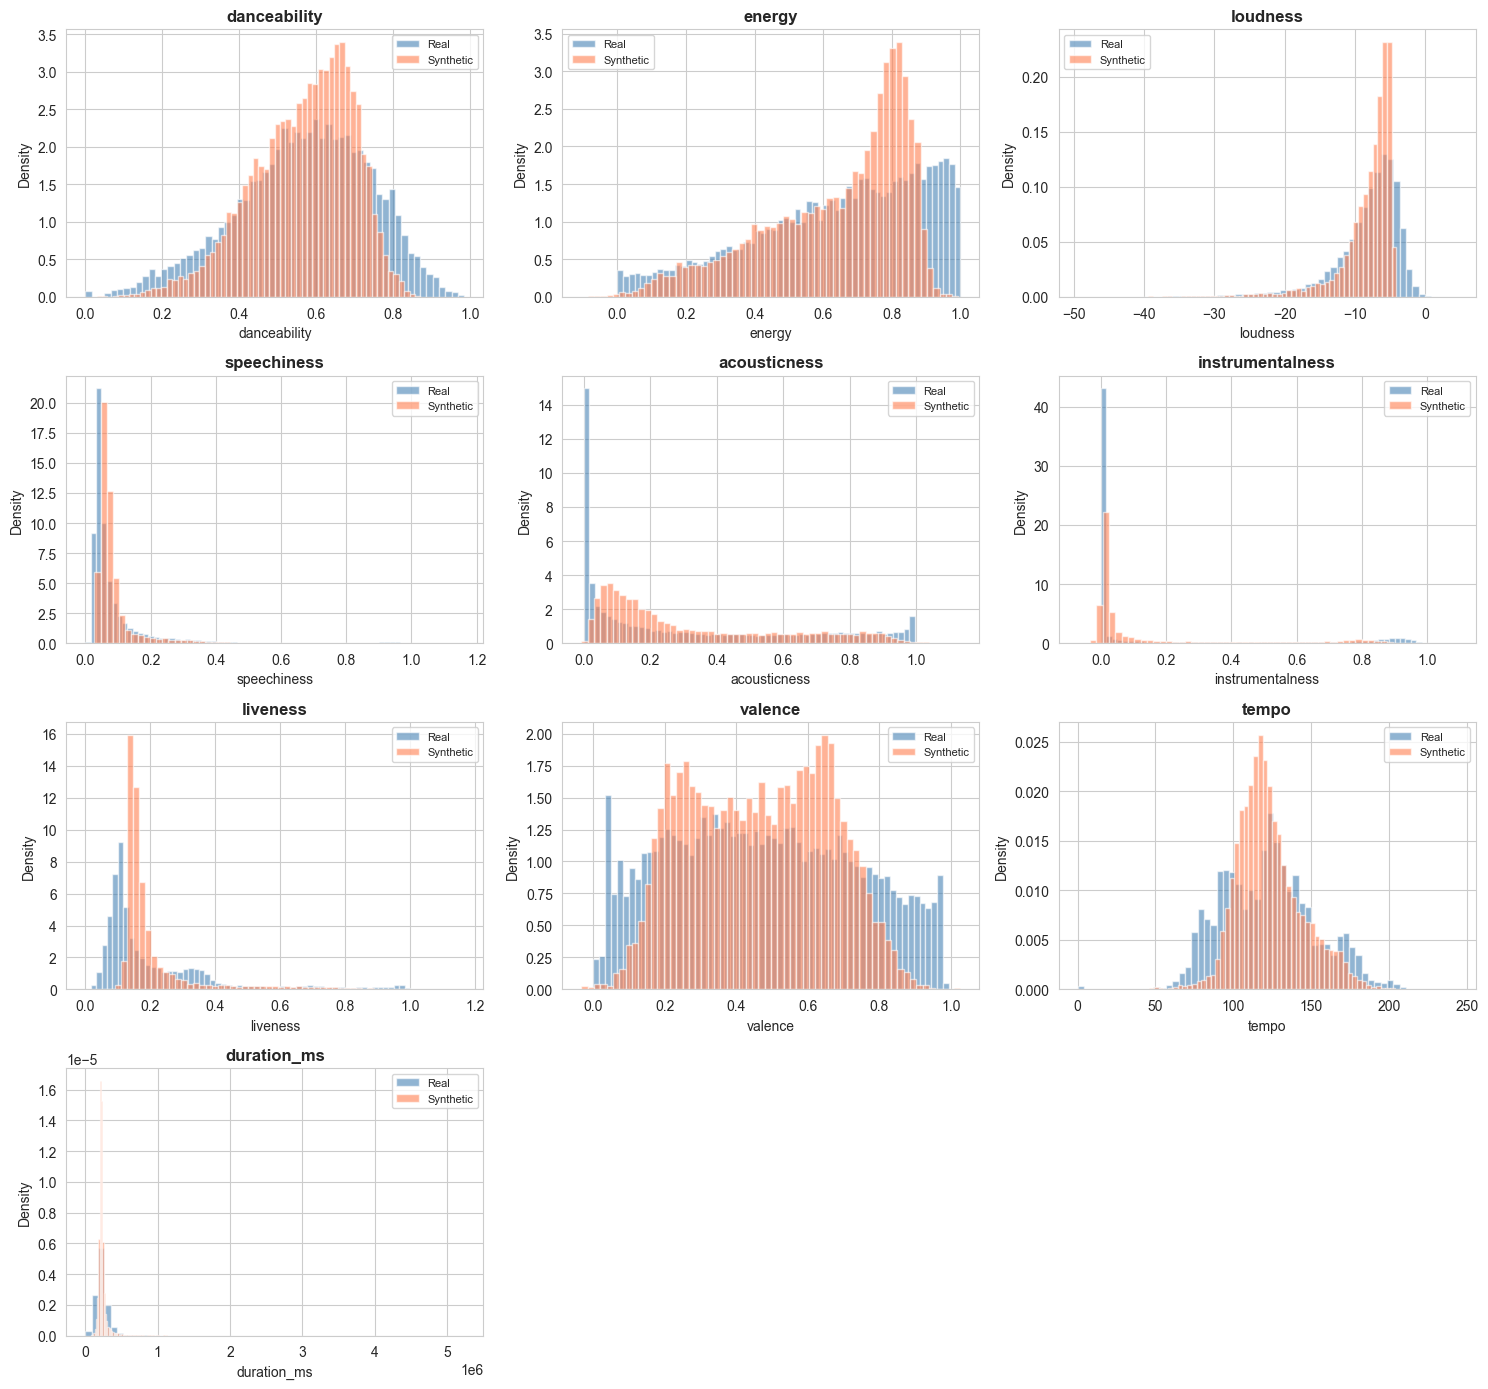

In [ ]:
# Comparing distributions feature-by-feature
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
axes = axes.flatten()

for i, feature in enumerate(AUDIO_FEATURES):
    axes[i].hist(df[feature], bins=60, alpha=0.6, label="Real",
                 color="steelblue", density=True, edgecolor="white")
    axes[i].hist(synthetic_df[feature], bins=60, alpha=0.6, label="Synthetic",
                 color="coral", density=True, edgecolor="white")
    axes[i].set_title(feature, fontweight="bold")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Density")
    axes[i].legend(fontsize=8)

# Hiding unused subplots
for j in range(len(AUDIO_FEATURES), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.savefig("figures/21_real_vs_synthetic_distributions.png", dpi=120, bbox_inches="tight")
plt.show()

In [38]:
from scipy.stats import ks_2samp

ks_results = []
for feature in AUDIO_FEATURES:
    stat, p_value = ks_2samp(df[feature].values, synthetic_df[feature].values)
    ks_results.append({
        "feature": feature,
        "ks_statistic": round(stat, 4),
        "p_value": round(p_value, 6)
    })

ks_df = pd.DataFrame(ks_results).sort_values("ks_statistic")
print(ks_df)
ks_df.to_csv("figures/ks_test_results.csv", index=False)

            feature  ks_statistic  p_value
0      danceability        0.1110      0.0
7           valence        0.1187      0.0
8             tempo        0.1695      0.0
1            energy        0.1736      0.0
2          loudness        0.1853      0.0
9       duration_ms        0.2298      0.0
4      acousticness        0.2737      0.0
3       speechiness        0.3644      0.0
6          liveness        0.4518      0.0
5  instrumentalness        0.5635      0.0


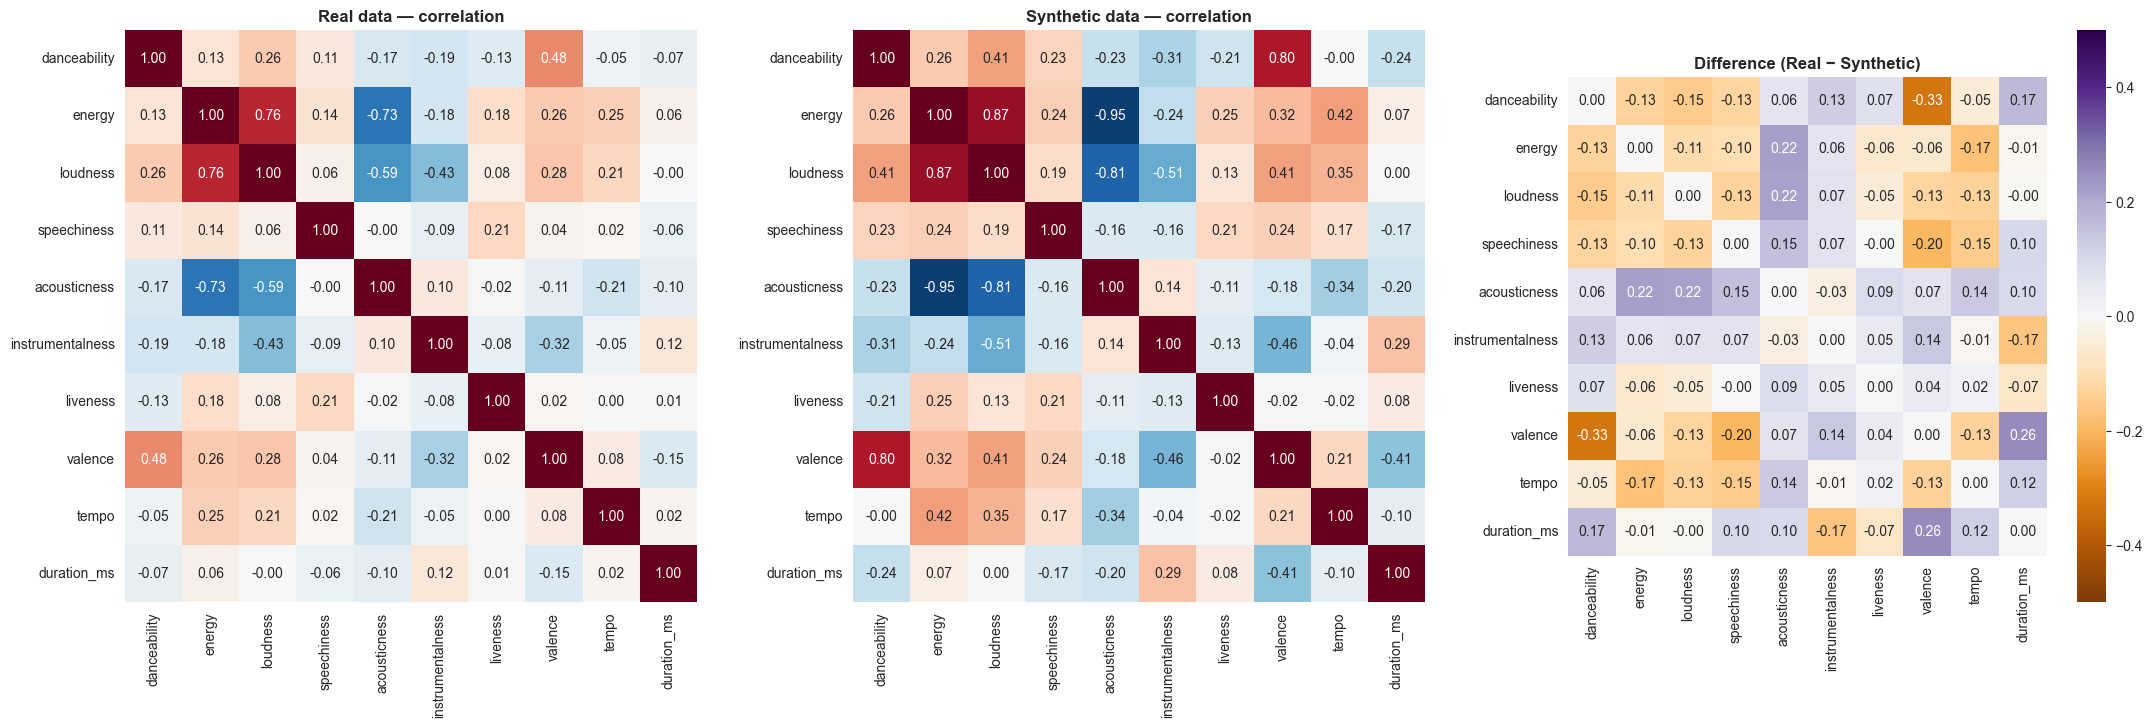

Frobenius norm of correlation difference: 1.2141
(Lower is better — 0 means perfect match)


In [ ]:
real_corr = df[AUDIO_FEATURES].corr(method="pearson")
synth_corr = synthetic_df[AUDIO_FEATURES].corr(method="pearson")
diff_corr = real_corr - synth_corr

fig, axes = plt.subplots(1, 3, figsize=(22, 7))

sns.heatmap(real_corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            ax=axes[0], square=True, vmin=-1, vmax=1, cbar=False)
axes[0].set_title("Real data — correlation", fontweight="bold")

sns.heatmap(synth_corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            ax=axes[1], square=True, vmin=-1, vmax=1, cbar=False)
axes[1].set_title("Synthetic data — correlation", fontweight="bold")

sns.heatmap(diff_corr, annot=True, fmt=".2f", cmap="PuOr", center=0,
            ax=axes[2], square=True, vmin=-0.5, vmax=0.5)
axes[2].set_title("Difference (Real − Synthetic)", fontweight="bold")

plt.tight_layout()
plt.savefig("figures/22_correlation_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

# Quantifying overall correlation similarity
frobenius_diff = np.sqrt(np.sum(diff_corr.values ** 2))
print(f"Frobenius norm of correlation difference: {frobenius_diff:.4f}")
print("(Lower is better — 0 means perfect match)")

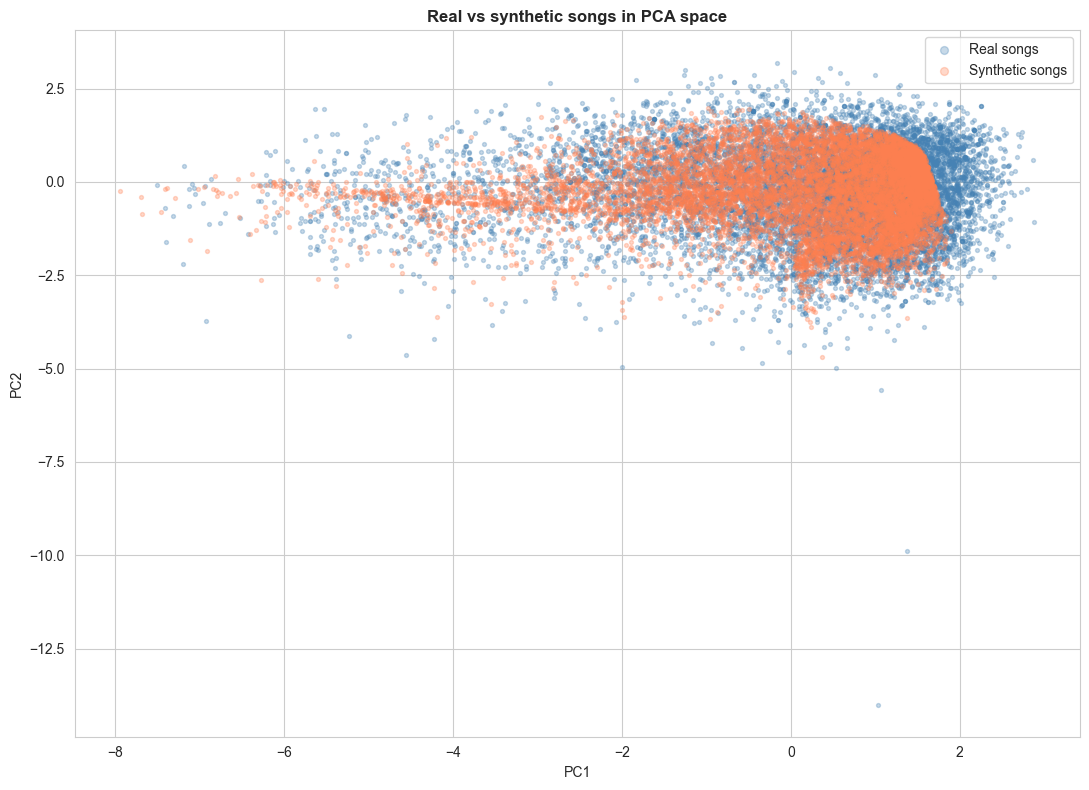

In [ ]:
# Using the same PCA fit from Phase 4
synth_scaled = scaler.transform(synthetic_df.values)
synth_pca = pca_2d.transform(synth_scaled)

# Using real PCA from before, re-fitting on a sample for visual clarity
real_sample_idx = df.sample(n=10000, random_state=RANDOM_SEED).index
real_pca = pca_2d.transform(X_full[real_sample_idx])

plt.figure(figsize=(11, 8))
plt.scatter(real_pca[:, 0], real_pca[:, 1], alpha=0.3, s=8,
            color="steelblue", label="Real songs")
plt.scatter(synth_pca[:, 0], synth_pca[:, 1], alpha=0.3, s=8,
            color="coral", label="Synthetic songs")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Real vs synthetic songs in PCA space", fontweight="bold")
plt.legend(markerscale=2)
plt.tight_layout()
plt.savefig("figures/23_real_vs_synthetic_pca.png", dpi=120, bbox_inches="tight")
plt.show()

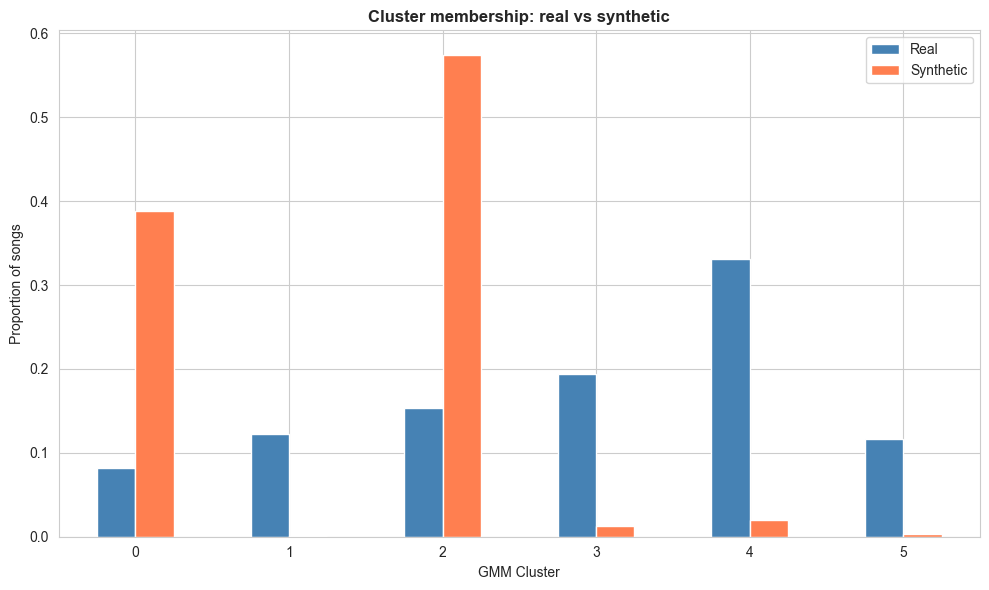

,Real,Synthetic
0,0.081974,0.3884
1,0.122526,0.0005
2,0.153693,0.5747
3,0.193430,0.0131
4,0.331439,0.0196
5,0.116939,0.0037


In [ ]:
# Assigning each synthetic song to a GMM cluster
synth_clusters = gmm_final.predict(synth_scaled)
real_cluster_dist = pd.Series(df["gmm_cluster"]).value_counts(normalize=True).sort_index()
synth_cluster_dist = pd.Series(synth_clusters).value_counts(normalize=True).sort_index()

comparison = pd.DataFrame({
    "Real": real_cluster_dist,
    "Synthetic": synth_cluster_dist
}).fillna(0)

ax = comparison.plot(kind="bar", figsize=(10, 6), color=["steelblue", "coral"])
ax.set_xlabel("GMM Cluster")
ax.set_ylabel("Proportion of songs")
ax.set_title("Cluster membership: real vs synthetic", fontweight="bold")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figures/24_cluster_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

comparison

Walking along latent dimension z1:
          danceability  energy   loudness  speechiness  acousticness  \
z1 value                                                               
-3.0             0.243   0.031 -34.377998        0.043         0.970   
-2.0             0.313   0.151 -20.650000        0.046         0.917   
-1.0             0.503   0.396  -9.688000        0.039         0.670   
 0.0             0.653   0.710  -6.266000        0.062         0.158   
 1.0             0.562   0.840  -4.857000        0.078         0.080   
 2.0             0.451   0.848  -4.698000        0.115         0.076   
 3.0             0.356   0.812  -5.136000        0.152         0.108   

          instrumentalness  liveness  valence       tempo    duration_ms  
z1 value                                                                  
-3.0                 0.922     0.097    0.090   89.947998  198575.734375  
-2.0                 0.824     0.126    0.149  104.900002  175036.125000  
-1.0            

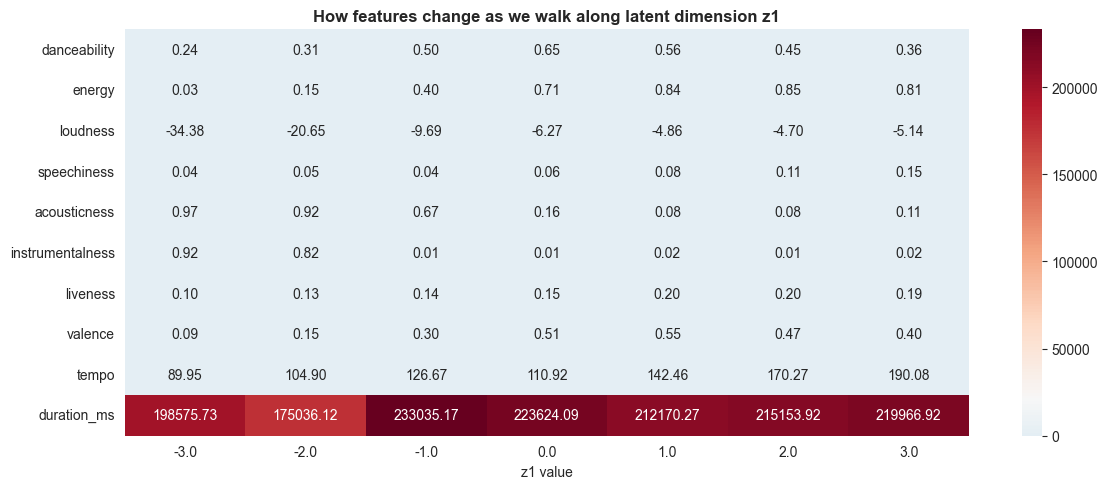

In [ ]:
# Generating songs by varying z1 (likely intensity) while holding others at 0
z_range = np.linspace(-3, 3, 7)  # walk from -3σ to +3σ
generated_along_z1 = []

with torch.no_grad():
    for z_val in z_range:
        z = torch.zeros(1, LATENT_DIM).to(device)
        z[0, 0] = z_val
        decoded = model.decode(z).cpu().numpy()
        generated_along_z1.append(scaler.inverse_transform(decoded)[0])

walk_z1 = pd.DataFrame(generated_along_z1, columns=AUDIO_FEATURES, index=z_range.round(2))
walk_z1.index.name = "z1 value"

print("Walking along latent dimension z1:")
print(walk_z1.round(3))

# Visualizing as a heatmap
plt.figure(figsize=(12, 5))
sns.heatmap(walk_z1.T, annot=True, fmt=".2f", cmap="RdBu_r", center=walk_z1.values.mean())
plt.title("How features change as we walk along latent dimension z1", fontweight="bold")
plt.xlabel("z1 value")
plt.tight_layout()
plt.savefig("figures/25_latent_walk_z1.png", dpi=120, bbox_inches="tight")
plt.show()

In [ ]:
# Generating 5 distinct synthetic songs and display them
np.random.seed(RANDOM_SEED)
with torch.no_grad():
    z_examples = torch.randn(5, LATENT_DIM).to(device)
    examples_scaled = model.decode(z_examples).cpu().numpy()

examples = pd.DataFrame(
    scaler.inverse_transform(examples_scaled),
    columns=AUDIO_FEATURES,
    index=[f"Synthetic Song {i+1}" for i in range(5)]
)
print("Example synthetic songs:")
print(examples.round(3).T)
examples.to_csv("figures/example_synthetic_songs.csv")

Example synthetic songs:
                  Synthetic Song 1  Synthetic Song 2  Synthetic Song 3  \
danceability              0.694000          0.539000          0.356000   
energy                    0.594000          0.373000          0.209000   
loudness                 -7.603000        -10.291000        -14.362000   
speechiness               0.057000          0.043000          0.042000   
acousticness              0.376000          0.726000          0.852000   
instrumentalness          0.003000          0.008000          0.099000   
liveness                  0.143000          0.143000          0.134000   
valence                   0.620000          0.372000          0.166000   
tempo                   111.138000        128.996002        117.702003   
duration_ms          209265.421875     213495.109375     223655.906250   

                  Synthetic Song 4  Synthetic Song 5  
danceability              0.681000          0.604000  
energy                    0.637000          0.4510